# CU-BEMS: AC anomaly detection and next-day electricity demand
Run cells in order with **Shift + Enter**. Q1 uses **15-minute mean AC power**; Q2 retains **hourly next-day forecasting**. Run all cells to regenerate charts and tables from `combined_by_floor.csv`. Old hourly outputs have been cleared.

**Scope:** Floor 7; baseline July 2018–June 2019; reporting July–December 2019. All results concern electrical power, not cooling output or diagnosed faults.

**Weather:** hourly Open-Meteo outdoor temperature, relative humidity and rain (`open-meteo-13.74N100.50E7m (2).csv`, Bangkok, exported in GMT) are shifted to Bangkok local time (UTC+7) to match CU-BEMS timestamps. They add context to anomaly events (hot-weather flags), feed two weather-aware forecasting models (M5, M6) and estimate how AC power responds to temperature for the setpoint simulator in `dashboard/app.py`.

**Dependencies:** pandas, numpy, matplotlib, scikit-learn. If a package is missing, run `%pip install pandas numpy matplotlib scikit-learn` in a separate cell, restart the kernel, and rerun. A bottleneck performance warning alone does not block this analysis.

**Important refinements to the proposal:** select a forecasting model on April–June validation, then reserve July–December for the final test. Do not pick and tune a model on the final test. Suspected closures are not verified holidays: retain them in main scoring and report a sensitivity analysis separately. The attached preliminary numbers are not hard-coded.

**Clearer charts:** larger labels, simple unit names and consistent colours. Blue = actual power, orange dashed = expected/forecast power, red = review flags. Main charts export as PNG and editable SVG. Statistical thresholds have a separate diagnostic chart. Run all cells with your source CSV, or use the final replot cell with existing exported CSVs.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display

# EDIT THESE SETTINGS if required
def _default_folder():
    # Prefer the folder this notebook runs from; fall back to the original project location.
    for candidate in [Path.cwd(), Path.home() / "Downloads/a_school/y4s1/SmartBuilding/Project/archive"]:
        if (candidate / "combined_by_floor.csv").exists():
            return candidate
    return Path.cwd()

FOLDER = Path(globals().get("DATA_FOLDER", _default_folder()))
INPUT_FILE = FOLDER / "combined_by_floor.csv"
FLOOR = 7
START = pd.Timestamp("2018-07-01")
VALIDATION_START = pd.Timestamp("2019-04-01")
TEST_START = pd.Timestamp("2019-07-01")
END = pd.Timestamp("2020-01-01")  # exclusive
MIN_MINUTES_PER_HOUR = 54  # 90% observed; use 60 for a strict sensitivity check
Q1_FREQ = "15min"
Q1_INTERVAL_HOURS = 0.25
MIN_MINUTES_PER_Q1_INTERVAL = 14  # observed valid minutes, BEFORE interpolation
Q1_MAX_GAP_MINUTES = 1  # bounded one-minute gaps only; set 0 to disable
Q1_PERSISTENCE_INTERVALS = 8  # 8 × 15 minutes = 2 hours
ACTIVE_MEAN_KW = 0.5
ON_THRESHOLD_KW = 0.5
MAX_VALID_KW = {}  # optional verified equipment limits, e.g. {"F7_z1_AC1(kW)": 100}
VERIFIED_CLOSURES = []  # only verified dates, e.g. ["2019-07-16"]
WEATHER_FILE = FOLDER / "open-meteo-13.74N100.50E7m (2).csv"
WEATHER_UTC_OFFSET_HOURS = 7  # Open-Meteo export is in GMT; CU-BEMS timestamps are Bangkok local time
WEATHER_LAT, WEATHER_LON = 13.743409, 100.495865
FETCH_MISSING_WEATHER = True  # top up hours lost by the time shift from the Open-Meteo archive API (cached)
HOT_DAY_QUANTILE = 0.9  # a "hot day" has daytime outdoor temperature above this baseline quantile for its calendar month
COMFORT_BAND_C = (23, 26)  # indoor temperature comfort band used for the comfort KPI
RH_BAND_PCT = (40, 60)  # indoor relative humidity band from the proposal
OUT = Path(globals().get("OUTPUT_FOLDER", FOLDER / "ac_analysis_outputs"))
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()

print("Input:", INPUT_FILE)
print("Outputs:", OUT)


Input: C:\Users\tankw\Smart Building Analytics\combined_by_floor.csv
Outputs: C:\Users\tankw\Smart Building Analytics\ac_analysis_outputs


In [2]:
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

BLUE = '#165DAB'
ORANGE = '#E69F00'
RED = '#C43D4D'
GREY = '#9AA5B1'
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 19, 'axes.titleweight': 'bold',
                     'axes.labelsize': 13, 'xtick.labelsize': 11, 'ytick.labelsize': 12,
                     'legend.fontsize': 11, 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': .15})

def unit_label(unit):
    match = re.search(r'z(\d+)_AC(\d+)', unit)
    return f'Zone {match[1]} · AC{match[2]}' if match else unit

MODEL_LABELS = {'M0 yesterday': 'Same hour yesterday', 'M0 last week': 'Same hour last week',
                'M1 median profile': 'Typical weekly pattern',
                'M2 calendar regression': 'Time-based regression',
                'M3 regression with lags': 'Regression + past demand',
                'M4 Random Forest': 'Random Forest',
                'M5 regression + weather': 'Regression + past demand + weather',
                'M6 Random Forest + weather': 'Random Forest + weather'}

def clear_figure(title, subtitle='', figsize=(13, 5.5)):
    fig, ax = plt.subplots(figsize=figsize)
    fig.suptitle(title, x=.08, y=.98, ha='left', fontsize=19, fontweight='bold')
    if subtitle:
        fig.text(.08, .90, subtitle, ha='left', fontsize=11, color='#526170')
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
    return fig, ax

def finish_clear(fig, name, note=''):
    if note:
        fig.text(.08, .025, note, fontsize=10, color='#526170', ha='left')
    fig.tight_layout(rect=[.02, .07 if note else .02, .99, .86])
    fig.savefig(OUT / name, dpi=240, bbox_inches='tight', facecolor='white')
    fig.savefig(OUT / Path(name).with_suffix('.svg'), bbox_inches='tight', facecolor='white')
    plt.show()

def week_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a\n%d %b'))
    ax.set_ylim(bottom=0)
    ax.margins(x=.015)

# def plot_anomaly(view, unit):
#     fig, ax = clear_figure(f'When does {unit_label(unit)} use more power than expected?',
#         '15-minute mean power · Example week selected for high estimated excess energy')
#     ax.plot(view.index, view['actual_kW'], color=BLUE, linewidth=2, label='Actual power')
#     ax.plot(view.index, view['expected_kW'], color=ORANGE, linewidth=2,
#             linestyle='--', label='Expected pattern')
#     flagged = view['flagged'].fillna(False).astype(bool)
#     ax.scatter(view.index[flagged], view.loc[flagged, 'actual_kW'], color=RED,
#                s=16, zorder=4, label='Flagged for review')
#     ax.set_ylabel('AC power (kW)'); week_axis(ax)
#     ax.legend(loc='upper left', ncol=3, frameon=False)
#     finish_clear(fig, '03_anomaly_timeseries.png',
#         'Flags include high use, after-hours operation and persistent deviations. Flags require investigation.')
#     # Keep the statistical threshold available in a separate technical chart.
#     fig, ax = clear_figure(f'{unit_label(unit)}: statistical threshold detail',
#                           'Only the statistical rule uses this upper threshold')
#     ax.plot(view.index, view['actual_kW'], color=BLUE, label='Actual power')
#     ax.plot(view.index, view['IQR_upper_kW'], color=GREY, linestyle=':', label='Statistical upper threshold')
#     ax.set_ylabel('AC power (kW)'); week_axis(ax); ax.legend(frameon=False)
#     finish_clear(fig, '03b_statistical_threshold.png')

def plot_anomaly(view, unit):
    fig, ax = clear_figure(
        f'When does {unit_label(unit)} use more power than expected?',
        '15-minute mean power · Example week selected for high estimated excess energy'
    )

    ax.plot(
        view.index, view['actual_kW'],
        color=BLUE, linewidth=2, label='Actual power'
    )
    ax.plot(
        view.index, view['expected_kW'],
        color=ORANGE, linewidth=2,
        linestyle='--', label='Expected pattern'
    )

    flagged = view['flagged'].fillna(False).astype(bool)
    ax.scatter(
        view.index[flagged], view.loc[flagged, 'actual_kW'],
        color=RED, s=16, zorder=4, label='Flagged for review'
    )

    ax.set_ylabel('AC power (kW)')
    week_axis(ax)

    # Move legend above the graph.
    ax.legend(
        loc='lower left',
        bbox_to_anchor=(0, 1.02),
        ncol=3,
        frameon=False,
        borderaxespad=0
    )

    finish_clear(
        fig, '03_anomaly_timeseries.png',
        'Flags include high use, after-hours operation and persistent deviations. Flags require investigation.'
    )

    # Separate statistical-threshold chart.
    fig, ax = clear_figure(
        f'{unit_label(unit)}: statistical threshold detail',
        'Only the statistical rule uses this upper threshold'
    )

    ax.plot(
        view.index, view['actual_kW'],
        color=BLUE, label='Actual power'
    )
    ax.plot(
        view.index, view['IQR_upper_kW'],
        color=GREY, linestyle=':',
        label='Statistical upper threshold'
    )

    ax.set_ylabel('AC power (kW)')
    week_axis(ax)

    ax.legend(
        loc='lower left',
        bbox_to_anchor=(0, 1.02),
        ncol=2,
        frameon=False,
        borderaxespad=0
    )

    finish_clear(fig, '03b_statistical_threshold.png')

def plot_ranking(ranking):
    ranked = ranking.sort_values('flagged_excess_kWh_est', ascending=False)
    fig, ax = clear_figure('Which AC units should be reviewed first?',
                          'Ranked by estimated excess energy during flagged periods · Jul–Dec 2019')
    bars = ax.barh([unit_label(x) for x in ranked.index], ranked['flagged_excess_kWh_est'],
                   color=[RED] + [BLUE]*(len(ranked)-1), height=.55)
    ax.invert_yaxis(); ax.set_xlabel('Estimated excess energy (kWh)')
    ax.bar_label(bars, labels=[f'{v:,.0f}' for v in ranked['flagged_excess_kWh_est']], padding=8)
    ax.set_xlim(0, max(1, ranked['flagged_excess_kWh_est'].max())*1.2)
    finish_clear(fig, '04_anomaly_ranking.png', 'Review priority only. Estimated excess energy is not verified savings.')
    fig, ax = clear_figure('How often is each AC unit flagged?',
                          'Percentage of valid 15-minute observations · Jul–Dec 2019')
    values = ranked['flagged_pct']
    bars = ax.barh([unit_label(x) for x in ranked.index], values, color=BLUE, height=.55)
    ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlim(0, max(1, values.max())*1.25)
    ax.bar_label(bars, labels=[f'{v:.1f}%' for v in values], padding=8)
    finish_clear(fig, '04b_flagged_share.png', 'Missing or invalid observations are excluded from the denominator.')

def plot_heatmap(heat):
    fig, ax = clear_figure('When are unusual AC patterns most common?',
                          'All selected units · Each column represents 15 minutes · Jul–Dec 2019')
    cmap = plt.get_cmap('YlOrRd').copy(); cmap.set_bad('#D9E0E5')
    im = ax.imshow(np.ma.masked_invalid(heat.to_numpy(dtype=float)), aspect='auto',
                   cmap=cmap, vmin=0, vmax=100, interpolation='nearest')
    ax.grid(False); ax.set_yticks(range(7), ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
    ax.set_xticks(range(0,96,8), [f'{i//4:02d}:00' for i in range(0,96,8)])
    ax.set_xlabel('Time of day'); fig.colorbar(im, ax=ax, pad=.02, label='Valid observations flagged (%)')
    finish_clear(fig, '05_anomaly_15min_day.png', 'Darker cells = a larger share flagged. Grey = no valid observations.')

# def plot_forecast(view, selected_model):
#     fig, ax = clear_figure('How closely does the forecast follow actual AC demand?',
#         'Hourly total for selected Floor 7 units · First reporting week · '+MODEL_LABELS.get(selected_model, selected_model))
#     ax.plot(view.index, view['floor_kW'], color=BLUE, linewidth=2, label='Actual demand')
#     ax.plot(view.index, view[selected_model], color=ORANGE, linewidth=2, linestyle='--', label='Next-day forecast')
#     ax.set_ylabel('AC demand (kW)'); week_axis(ax); ax.legend(ncol=2, frameon=False, loc='upper left')
#     finish_clear(fig, '06_actual_vs_forecast.png', 'Each forecast covers the next 24 hourly intervals. The model stays fixed throughout the test period.')

def plot_forecast(view, selected_model):
    fig, ax = clear_figure(
        'How closely does the forecast follow actual AC demand?',
        'Hourly total for selected Floor 7 units · First reporting week · '
        + MODEL_LABELS.get(selected_model, selected_model)
    )

    ax.plot(
        view.index, view['floor_kW'],
        color=BLUE, linewidth=2,
        label='Actual demand'
    )

    ax.plot(
        view.index, view[selected_model],
        color=ORANGE, linewidth=2, linestyle='--',
        label='Next-day forecast'
    )

    ax.set_ylabel('AC demand (kW)')
    week_axis(ax)

    # Place the legend above the graph.
    ax.legend(
        loc='lower left',
        bbox_to_anchor=(0, 1.02),
        ncol=2,
        frameon=False,
        borderaxespad=0
    )

    finish_clear(
        fig,
        '06_actual_vs_forecast.png',
        'Each forecast covers the next 24 hourly intervals. '
        'The model stays fixed throughout the test period.'
    )


def plot_accuracy(metrics, selected_model):
    values = metrics['MAE_kW'].sort_values()
    fig, ax = clear_figure('Which forecasting method has the lowest average error?',
                          'Jul–Dec 2019 · Same evaluation hours for every model · Lower is better')
    labels = [MODEL_LABELS.get(x,x)+(' (selected)' if x==selected_model else '') for x in values.index]
    bars = ax.barh(labels, values, color=[BLUE if x==selected_model else '#B8C5D3' for x in values.index], height=.55)
    ax.invert_yaxis(); ax.set_xlabel('Mean absolute error (kW)')
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in values], padding=7)
    ax.set_xlim(0, max(1,values.max())*1.2)
    finish_clear(fig, '07_forecast_MAE.png', 'Selected model chosen using Apr–Jun validation data. These bars show performance on the later test period.')

def plot_hour_error(error_by_hour):
    values = error_by_hour.reindex(range(24))
    fig, ax = clear_figure('At what time is demand hardest to predict?',
                          'Selected model · Average absolute error by hour · Jul–Dec 2019')
    ax.bar(range(24), values, color=[RED if pd.notna(v) and v==values.max() else BLUE for v in values])
    ax.set_xticks(range(0,24,2), [f'{h:02d}:00' for h in range(0,24,2)])
    ax.set_ylabel('Mean absolute error (kW)'); ax.set_xlabel('Hour of day')
    finish_clear(fig, '08_forecast_error_by_hour.png', 'Higher bars indicate larger forecasting errors. Missing hours are left blank.')

def plot_nextday(next24, issue_time):
    fig, ax = clear_figure('What AC demand is expected over the next 24 hours?',
                          f'Historical demonstration for {issue_time:%d %b %Y} · Hourly forecast')
    s = next24['predicted_kW']; ax.plot(s.index, s, color=BLUE, linewidth=2.5, marker='o', markersize=4)
    if s.notna().any():
        peak = s.idxmax(); ax.scatter([peak], [s.loc[peak]], color=RED, s=65, zorder=5)
        ax.annotate(f'Predicted peak\n{peak:%H:%M}: {s.loc[peak]:.1f} kW', xy=(peak,s.loc[peak]),
                    xytext=(20,25), textcoords='offset points', fontsize=12,
                    arrowprops={'arrowstyle':'->','color':RED}, color=RED)
    ax.set_xlim(s.index.min(), s.index.max())
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=list(range(0,24,2)) + [23])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.set_ylim(0,max(1,s.max())*1.4); ax.set_xlabel('Time of day'); ax.set_ylabel('Predicted AC demand (kW)')
    finish_clear(fig, '09_next_24_hours_forecast.png', 'Routine-day pattern only. Holiday closures are not modelled, including New Year’s Day.')


## 1. Read only the selected floor and check quality
Floor, zone and AC number remain in every equipment identifier. No missing value becomes zero. Values below zero and supplied engineering-limit violations are masked; large positive readings are otherwise retained for investigation. Flat-lined positive values are reported as **suspected stale sensor readings**, not automatically deleted. The script does not infer physical limits from the largest observed value.


Reading 29 Floor 7 columns...
Invalid dates: 0


,baseline_mean_kW,missing_pct,active_selected
F7_z1_AC1(kW),0.00,0.61,False
F7_z1_AC2(kW),0.06,0.61,False
F7_z1_AC3(kW),0.07,0.61,False
F7_z1_AC4(kW),8.73,3.83,True
F7_z2_AC1(kW),6.41,3.83,True
F7_z4_AC1(kW),5.74,3.83,True
F7_z5_AC1(kW),2.51,3.83,True


Selected active units: ['F7_z1_AC4(kW)', 'F7_z2_AC1(kW)', 'F7_z4_AC1(kW)', 'F7_z5_AC1(kW)']
Positive flatline candidates: 0


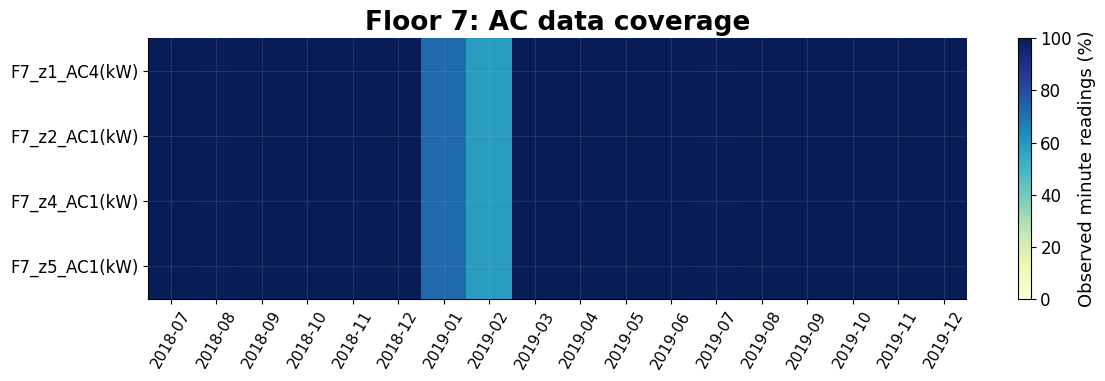

In [3]:
headers = pd.read_csv(INPUT_FILE, nrows=0).columns.tolist()
prefix = f"F{FLOOR}_"
floor_columns = [c for c in headers if c.startswith(prefix)]
if not floor_columns:
    raise ValueError(f"No columns beginning with {prefix}; check the combined file.")
print(f"Reading {len(floor_columns)} Floor {FLOOR} columns...", flush=True)
raw = pd.read_csv(INPUT_FILE, usecols=["Date"] + floor_columns, low_memory=False)
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
print("Invalid dates:", int(raw["Date"].isna().sum()))
raw = raw.dropna(subset=["Date"])
if raw["Date"].duplicated().any():
    raise ValueError("Duplicate timestamps. Check the merge; do not average floors together.")
raw = raw.set_index("Date").sort_index()
raw = raw.loc[(raw.index >= START) & (raw.index < END)]
minute_index = pd.date_range(START, END - pd.Timedelta(minutes=1), freq="min")
raw = raw.reindex(minute_index).apply(pd.to_numeric, errors="coerce")
raw.index.name = "Date"
ac_columns = [c for c in floor_columns if re.search(r"_z\d+_AC\d+\(kW\)$", c)]
if not ac_columns:
    raise ValueError("No AC columns found. Inspect the input headers.")
ac = raw[ac_columns].copy()
invalid = ac.lt(0) | ~np.isfinite(ac)
for c, limit in MAX_VALID_KW.items():
    if c in ac:
        invalid[c] |= ac[c].gt(limit)
ac = ac.mask(invalid)
training_minute = ac.loc[ac.index < TEST_START]
active_units = training_minute.mean().loc[lambda s: s >= ACTIVE_MEAN_KW].index.tolist()
if not active_units:
    raise ValueError("No active units selected. Inspect data and ACTIVE_MEAN_KW.")
ac = ac[active_units]
monthly_coverage = ac.notna().resample("MS").mean() * 100
quality = pd.DataFrame({"baseline_mean_kW": training_minute.mean(),
                        "missing_pct": ac.reindex(columns=ac_columns).isna().mean()*100,
                        "active_selected": [c in active_units for c in ac_columns]})
# Missing percentage of excluded units must use their actual data, not reindexed active units
quality["missing_pct"] = raw[ac_columns].isna().mean()*100
quality.to_csv(OUT / "unit_quality.csv")
monthly_coverage.to_csv(OUT / "monthly_coverage.csv")
display(quality.round(2))
print("Selected active units:", active_units)

# Positive flatline runs >= 6 hours: audit candidates only
flatline_rows = []
for c in active_units:
    s = ac[c]
    groups = s.ne(s.shift()).cumsum()
    audit = pd.DataFrame({"Date": s.index, "kW": s.values, "run": groups.values})
    runs = audit.groupby("run").agg(start=("Date","min"), end=("Date","max"),
                                     minutes=("Date","size"), kW=("kW","first"))
    runs = runs.loc[runs["minutes"].ge(360) & runs["kW"].gt(ON_THRESHOLD_KW)]
    for _, row in runs.iterrows():
        flatline_rows.append({"unit": c, **row.to_dict()})
flatlines = pd.DataFrame(flatline_rows, columns=["unit", "start", "end", "minutes", "kW"])
flatlines.to_csv(OUT / "suspected_flatlines.csv", index=False)
print("Positive flatline candidates:", len(flatlines))
plt.figure(figsize=(12, 4))
plt.imshow(monthly_coverage.T, aspect="auto", vmin=0, vmax=100, cmap="YlGnBu")
plt.yticks(range(len(active_units)), active_units)
plt.xticks(range(len(monthly_coverage)), monthly_coverage.index.strftime("%Y-%m"), rotation=60)
plt.colorbar(label="Observed minute readings (%)")
plt.title(f"Floor {FLOOR}: AC data coverage")
save_plot("01_data_coverage.png")


## 1b. Outdoor weather (Open-Meteo) and indoor conditions
The Open-Meteo export labels hours in **GMT**; CU-BEMS uses **Bangkok local time (UTC+7)** (AC switches on around 07:00 local). Each weather timestamp is shifted by +7 hours. The shift leaves the first 7 local hours of July 2018 and most of 1 January 2020 uncovered, so missing hours are optionally fetched from the [Open-Meteo archive API](https://open-meteo.com/en/docs/historical-weather-api) and cached in the output folder. If the download fails, those hours stay missing.

Open-Meteo temperature and humidity are instantaneous values at the labelled hour; rain is the sum over the **preceding** hour. To match interval-start labels (an hourly value at 09:00 covers 09:00–10:00):
- hourly temperature/RH = mean of the readings at the start and end of the interval
- hourly rain = the value labelled at the end of the interval
- 15-minute temperature/RH = time interpolation at the interval midpoint

Indoor temperature and RH come from each zone's `S1` sensor (values outside 5–45 °C or 0–100 % are masked).

Missing instantaneous weather hours: 0 of 13202
Hot-day thresholds by month (baseline daytime mean, q90%, °C): {1: 30.6, 2: 32.1, 3: 33.0, 4: 35.1, 5: 34.6, 6: 32.0, 7: 30.8, 8: 30.0, 9: 31.0, 10: 30.5, 11: 31.2, 12: 32.3}
Hot days in reporting period: 55


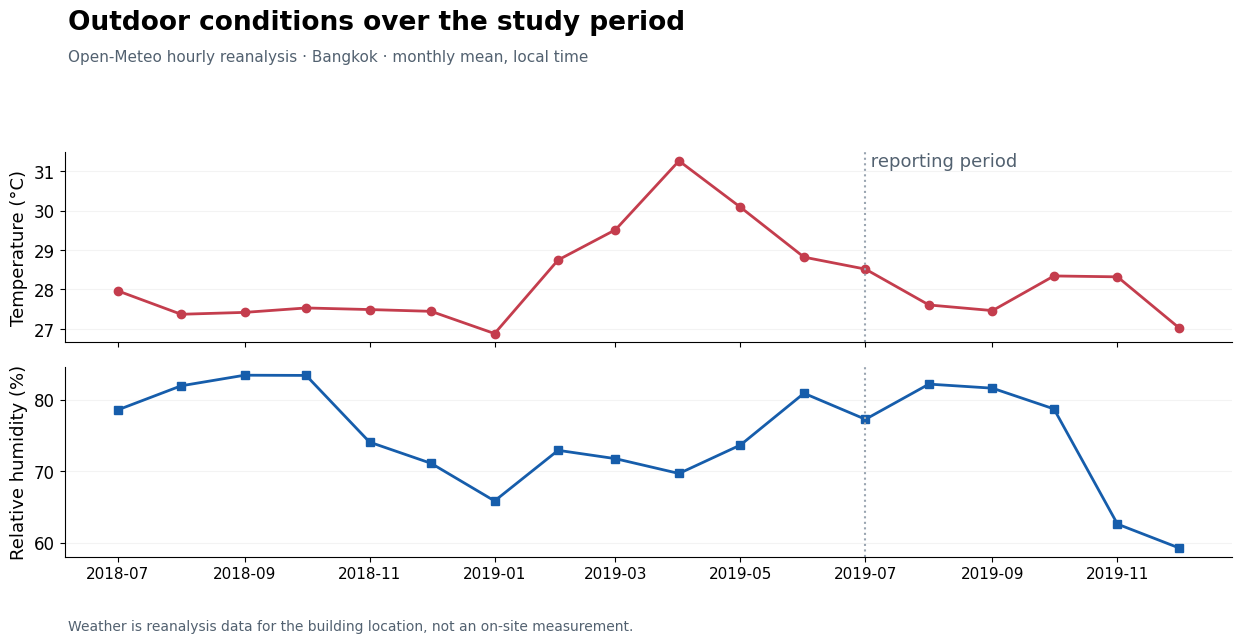

In [4]:
def read_open_meteo(source):
    # Open-Meteo CSV: three metadata lines, then hourly rows in GMT
    frame = pd.read_csv(source, skiprows=3)
    names = {}
    for c in frame.columns:
        if c.startswith("temperature_2m"): names[c] = "outdoor_temp_C"
        elif c.startswith("relative_humidity_2m"): names[c] = "outdoor_rh_pct"
        elif c.startswith("rain"): names[c] = "rain_mm"
        elif c == "time": names[c] = "Date"
    frame = frame.rename(columns=names)
    frame["Date"] = pd.to_datetime(frame["Date"]) + pd.Timedelta(hours=WEATHER_UTC_OFFSET_HOURS)
    frame = frame.set_index("Date")[["outdoor_temp_C", "outdoor_rh_pct", "rain_mm"]].astype(float)
    return frame.loc[~frame.index.duplicated()].sort_index()

# Instantaneous hourly readings needed: the analysis period plus the next-day demonstration
weather_needed = pd.date_range(START - pd.Timedelta(hours=1), END + pd.Timedelta(days=1), freq="h")
weather_raw = read_open_meteo(WEATHER_FILE)
missing_hours = weather_needed.difference(weather_raw.index)
WEATHER_CACHE = OUT / "open_meteo_topup_local.csv"
if len(missing_hours) and FETCH_MISSING_WEATHER:
    topup = pd.read_csv(WEATHER_CACHE, index_col=0, parse_dates=True) if WEATHER_CACHE.exists() else None
    if topup is None or len(missing_hours.difference(topup.index)):
        gmt = missing_hours - pd.Timedelta(hours=WEATHER_UTC_OFFSET_HOURS)
        url = ("https://archive-api.open-meteo.com/v1/archive"
               f"?latitude={WEATHER_LAT}&longitude={WEATHER_LON}"
               f"&start_date={gmt.min():%Y-%m-%d}&end_date={gmt.max():%Y-%m-%d}"
               "&hourly=relative_humidity_2m,temperature_2m,rain&timezone=GMT&format=csv")
        try:
            topup = read_open_meteo(url)
            topup.to_csv(WEATHER_CACHE)
            print(f"Downloaded {len(topup)} hourly weather rows from the Open-Meteo archive API")
        except Exception as error:
            topup = None
            print("Weather top-up failed; those hours stay missing:", error)
    if topup is not None:
        weather_raw = weather_raw.combine_first(topup)
instant = weather_raw.reindex(weather_needed)
print("Missing instantaneous weather hours:", int(instant["outdoor_temp_C"].isna().sum()), "of", len(instant))

# Hourly interval values labelled by interval start (same convention as the AC data)
weather_hourly = pd.DataFrame({
    "outdoor_temp_C": instant["outdoor_temp_C"].rolling(2).mean().shift(-1),
    "outdoor_rh_pct": instant["outdoor_rh_pct"].rolling(2).mean().shift(-1),
    "rain_mm": instant["rain_mm"].shift(-1)}).loc[START:END + pd.Timedelta(hours=23)]
weather_hourly.index.name = "Date"

# 15-minute values: interpolate temperature/RH at each interval midpoint; rain keeps its hourly total
grid_15 = pd.date_range(START, END + pd.Timedelta(days=1), freq="15min", inclusive="left")
midpoints = grid_15 + pd.Timedelta(minutes=7.5)
interp = instant[["outdoor_temp_C", "outdoor_rh_pct"]].reindex(instant.index.union(midpoints)).interpolate("time", limit_area="inside")
weather_15min = interp.reindex(midpoints).set_axis(grid_15)
weather_15min["rain_mm"] = weather_hourly["rain_mm"].reindex(grid_15, method="ffill")

# Hot days: daytime (08:00-17:00) mean outdoor temperature above the baseline quantile
daytime = weather_hourly.loc[(weather_hourly.index.hour >= 8) & (weather_hourly.index.hour < 17), "outdoor_temp_C"]
daytime_temp = daytime.resample("D").mean()
# Seasonal threshold: compare each day with baseline days of the same calendar month
# (a single annual threshold would only ever fire in the April-May hot season)
baseline_days = daytime_temp.loc[daytime_temp.index < TEST_START]
monthly_threshold = baseline_days.groupby(baseline_days.index.month).quantile(HOT_DAY_QUANTILE)
hot_day_threshold_by_day = pd.Series(daytime_temp.index.month, index=daytime_temp.index).map(monthly_threshold)
hot_days = daytime_temp.index[daytime_temp > hot_day_threshold_by_day]
weather_15min["hot_day"] = weather_15min.index.normalize().isin(hot_days)
weather_hourly.to_csv(OUT / "weather_hourly_local.csv")
print(f"Hot-day thresholds by month (baseline daytime mean, q{HOT_DAY_QUANTILE:.0%}, °C):",
      monthly_threshold.round(1).to_dict())
print("Hot days in reporting period:", int((hot_days >= TEST_START).sum()))

# Indoor conditions for each AC zone (one S1 sensor per zone)
def zone_of(unit):
    return re.search(r"_z(\d+)_", unit)[1]

indoor_columns = {}
for z in sorted({zone_of(c) for c in active_units}):
    for kind, column in [("temp", f"F{FLOOR}_z{z}_S1(degC)"), ("rh", f"F{FLOOR}_z{z}_S1(RH%)")]:
        if column in raw:
            indoor_columns[(z, kind)] = column
indoor_raw = raw[list(indoor_columns.values())]
indoor_raw = indoor_raw.mask(indoor_raw.lt(0))
for (z, kind), column in indoor_columns.items():
    low, high = (5, 45) if kind == "temp" else (0, 100)
    indoor_raw[column] = indoor_raw[column].where(indoor_raw[column].between(low, high))
indoor_15min = indoor_raw.resample(Q1_FREQ).mean().where(indoor_raw.resample(Q1_FREQ).count() >= MIN_MINUTES_PER_Q1_INTERVAL)
indoor_hourly = indoor_raw.resample("h").mean().where(indoor_raw.resample("h").count() >= MIN_MINUTES_PER_HOUR)

def indoor_series(frame, unit, kind):
    column = indoor_columns.get((zone_of(unit), kind))
    return frame[column] if column else pd.Series(np.nan, index=frame.index)

monthly_weather = weather_hourly.loc[START:END - pd.Timedelta(hours=1)].resample("MS").mean()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
fig.suptitle("Outdoor conditions over the study period", x=.08, y=.98, ha="left", fontsize=19, fontweight="bold")
fig.text(.08, .90, "Open-Meteo hourly reanalysis · Bangkok · monthly mean, local time", ha="left", fontsize=11, color="#526170")
ax.plot(monthly_weather.index, monthly_weather["outdoor_temp_C"], color=RED, marker="o", linewidth=2)
ax.set_ylabel("Temperature (°C)")
ax2.plot(monthly_weather.index, monthly_weather["outdoor_rh_pct"], color=BLUE, marker="s", linewidth=2)
ax2.set_ylabel("Relative humidity (%)")
for a in (ax, ax2):
    a.grid(axis="x", visible=False)
    a.axvline(TEST_START, color=GREY, linestyle=":")
ax.text(TEST_START, ax.get_ylim()[1], " reporting period", color="#526170", va="top")
finish_clear(fig, "01b_outdoor_weather.png", "Weather is reanalysis data for the building location, not an on-site measurement.")


## 2. Separate Q1 and Q2 preparation, schedules and closure checks
**Q1:** 15-minute mean power (kW), requiring at least **14 of 15 observed valid minute readings per unit before interpolation**. Only bounded one-minute gaps are filled, within baseline/reporting periods separately. Longer gaps remain missing. Filled minutes and intervals are exported separately; accepted incomplete intervals use an observed-mean estimate. Estimated energy = mean kW × 0.25 hours.

**Q2:** observed hourly averages only (at least 54 of 60 valid minute readings per unit), unchanged. A missing unit makes the hourly floor total missing. Forecast targets are never interpolated.

Q1 schedules use each unit's baseline **15-minute slot × day-of-week median** above 0.5 kW. The expected baseline uses **15-minute slot × weekday/weekend means**. These historical proxies require facilities-manager review. Suspected closures still require 24 valid observed floor hours; only manually verified closures are excluded from primary training and scoring.


Valid Q1 reporting unit-intervals: 70511
Valid observed baseline floor hours: 8255
Valid observed reporting floor hours: 4405
Suspected closure weekdays (NOT verified): 24


,count,max,mean
Date,,,
2018-07-30,24,0.0,0.0
2018-08-13,24,0.0,0.0
2018-10-23,24,0.0,0.0
2018-12-05,24,0.0,0.0
2018-12-10,24,0.0,0.0
2018-12-31,24,0.0,0.0
2019-01-01,24,0.0,0.0
2019-02-19,24,0.0,0.0
2019-04-12,24,0.0,0.0


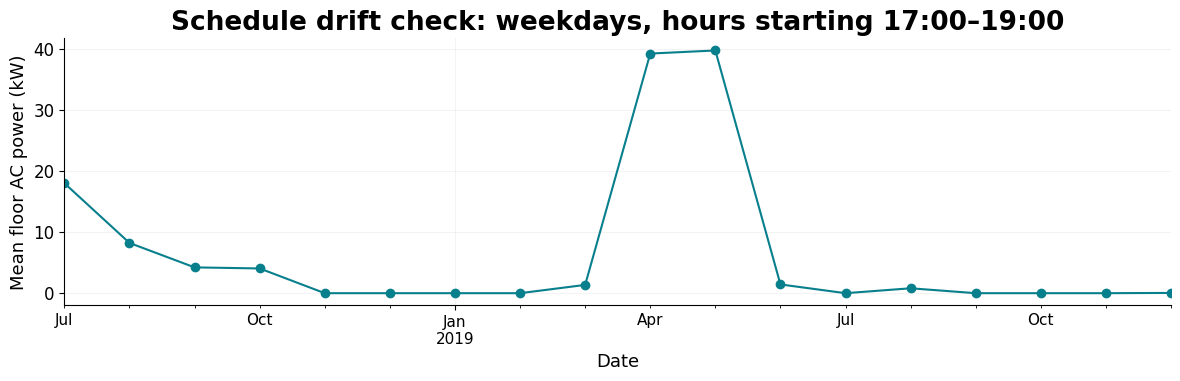

In [5]:
observed_counts = ac.resample("h").count()
observed_hourly = ac.resample("h").mean().where(observed_counts >= MIN_MINUTES_PER_HOUR)
floor_demand = observed_hourly.sum(axis=1, min_count=len(active_units)).rename("floor_kW")

# Q1 retrospective interpolation; never crosses the baseline/test boundary

def fill_short_gaps(frame, max_gap=1):
    result = frame.copy()
    for c in frame:
        s = frame[c]
        missing = s.isna()
        runs = missing.ne(missing.shift()).cumsum()
        size = missing.groupby(runs).transform("sum")
        allowed = missing & size.le(max_gap)
        candidate = s.interpolate(method="time", limit_area="inside")
        result[c] = s.where(~allowed, candidate)
    return result

filled = pd.concat([fill_short_gaps(ac.loc[ac.index < TEST_START], Q1_MAX_GAP_MINUTES),
                    fill_short_gaps(ac.loc[ac.index >= TEST_START], Q1_MAX_GAP_MINUTES)]).sort_index()
q1_observed_counts = ac.resample(Q1_FREQ).count()
anomaly_15min = filled.resample(Q1_FREQ).mean().where(
    q1_observed_counts >= MIN_MINUTES_PER_Q1_INTERVAL)
imputed_minutes = (filled.notna() & ac.isna()).resample(Q1_FREQ).sum()
verified_dates = pd.DatetimeIndex(pd.to_datetime(VERIFIED_CLOSURES)).normalize()
# Q2 masks stay on the HOURLY index.
verified_mask = floor_demand.index.normalize().isin(verified_dates)
training_mask = (floor_demand.index < TEST_START) & ~verified_mask
report_mask = (floor_demand.index >= TEST_START) & ~verified_mask
floor_demand = floor_demand.mask(verified_mask)
how = pd.Series(floor_demand.index.dayofweek*24 + floor_demand.index.hour,
                index=floor_demand.index, name="hour_of_week")
# Q1 masks and slot keys are separate from Q2.
q1_verified_mask = anomaly_15min.index.normalize().isin(verified_dates)
q1_training_mask = (anomaly_15min.index < TEST_START) & ~q1_verified_mask
q1_report_mask = (anomaly_15min.index >= TEST_START) & ~q1_verified_mask
anomaly_15min.loc[q1_verified_mask] = np.nan
q1_slot = pd.Series(anomaly_15min.index.hour*4 + anomaly_15min.index.minute//15,
                    index=anomaly_15min.index, name="slot_of_day")
q1_slot_week = (anomaly_15min.index.dayofweek*96 + q1_slot).rename("slot_of_week")
baseline_profile = anomaly_15min.loc[q1_training_mask].groupby(q1_slot_week.loc[q1_training_mask]).median()
schedule_table = baseline_profile.gt(ON_THRESHOLD_KW).where(baseline_profile.notna())
schedule_table.index.name = "slot_of_week"
schedule_table.to_csv(OUT / "derived_unit_schedule_15min.csv")
q1_quality = pd.concat({"observed_minutes": q1_observed_counts,
                        "imputed_minutes": imputed_minutes,
                        "has_interpolation": imputed_minutes.gt(0),
                        "valid_interval": anomaly_15min.notna()}, axis=1)
q1_quality.to_csv(OUT / "q1_15min_interval_quality.csv")
print("Valid Q1 reporting unit-intervals:", int(anomaly_15min.loc[q1_report_mask].notna().sum().sum()))

by_day = floor_demand.resample("D").agg(["count", "max", "mean"])
suspected = by_day.loc[(by_day.index.dayofweek < 5) & (by_day["count"] == 24)
                      & by_day["max"].le(0.5)].copy()
suspected.to_csv(OUT / "suspected_closure_days_unverified.csv")
print("Valid observed baseline floor hours:", int(floor_demand.loc[training_mask].notna().sum()))
print("Valid observed reporting floor hours:", int(floor_demand.loc[report_mask].notna().sum()))
print("Suspected closure weekdays (NOT verified):", len(suspected))
display(suspected.head(10))

# Descriptive check of the schedule drift mentioned in the proposal
weekday_evening = floor_demand.loc[(floor_demand.index.dayofweek < 5)
                                 & floor_demand.index.hour.isin([17,18,19])]
evening_month = weekday_evening.resample("MS").mean()
evening_month.to_csv(OUT / "weekday_17_to_19_monthly_kW.csv")
evening_month.plot(marker="o", color="#087f8c")
plt.ylabel("Mean floor AC power (kW)")
plt.title("Schedule drift check: weekdays, hours starting 17:00–19:00")
save_plot("02_evening_schedule_drift.png")


## 3. RQ1 — 15-minute high-consumption anomaly detection
**Question:** Which zones and individual AC units exhibit unusually high electricity consumption compared with their own historical operating patterns, and when do these anomalies occur?

IQR thresholds compare the same **15-minute slot and day of the week**; the expected baseline compares the same **15-minute slot and weekday/weekend type**. Both are fitted on the baseline only. Statistical flags require power > 0.5 kW. After-hours flags require a known historical schedule. Persistent positive residuals require **8 consecutive valid 15-minute intervals (2 hours)**; missing intervals break runs.

Events join consecutive flagged intervals within one unit. Duration = interval count × 0.25 hours; estimated positive excess energy = max(actual − expected, 0) × 0.25 hours. Rankings and heatmaps use valid 15-minute intervals. Flags indicate review priorities, not diagnosed faults or proven savings. Lower-consumption detection is not included.


,valid_intervals,flagged_intervals,after_hours_flagged_intervals,flagged_pct,valid_hours,flagged_hours,after_hours_flagged_hours,events,longest_event_hours,flagged_excess_kWh_est,events_on_hot_days
unit,,,,,,,,,,,
F7_z1_AC4(kW),17627,3203,441,18.17,4406.75,800.75,110.25,230,9.75,5785.47,77
F7_z4_AC1(kW),17628,2332,196,13.23,4407.00,583.00,49.00,173,8.00,3730.52,68
F7_z2_AC1(kW),17628,3099,420,17.58,4407.00,774.75,105.00,215,9.75,3663.49,75
F7_z5_AC1(kW),17628,949,171,5.38,4407.00,237.25,42.75,94,8.25,1424.48,48


,unit,start,end_exclusive,duration_hours,peak_kW,excess_kWh_est,after_hours_hours,has_statistical_flag,has_persistent_flag,mean_outdoor_temp_C,mean_indoor_temp_C,on_hot_day
37,F7_z1_AC4(kW),2019-07-27 07:30:00,2019-07-27 17:15:00,9.75,35.94,253.88,9.75,True,True,29.75,17.38,False
17,F7_z1_AC4(kW),2019-07-13 07:30:00,2019-07-13 16:45:00,9.25,36.87,245.43,9.25,True,True,31.66,18.93,True
6,F7_z1_AC4(kW),2019-07-06 07:30:00,2019-07-06 17:00:00,9.50,35.39,240.69,9.50,True,True,29.77,17.39,False
244,F7_z2_AC1(kW),2019-07-13 07:30:00,2019-07-13 16:45:00,9.25,27.55,225.83,9.25,True,True,31.66,21.04,True
264,F7_z2_AC1(kW),2019-07-27 07:30:00,2019-07-27 17:15:00,9.75,26.76,184.95,9.75,True,True,29.75,20.62,False
475,F7_z4_AC1(kW),2019-07-27 09:15:00,2019-07-27 17:15:00,8.00,31.39,181.78,8.00,True,True,30.36,19.73,False
272,F7_z2_AC1(kW),2019-08-03 09:45:00,2019-08-03 17:15:00,7.50,26.43,174.19,7.50,True,True,27.61,20.37,False
190,F7_z1_AC4(kW),2019-11-23 10:45:00,2019-11-23 17:45:00,7.00,35.45,169.52,7.00,True,True,32.90,17.25,True
406,F7_z2_AC1(kW),2019-11-23 10:45:00,2019-11-23 17:45:00,7.00,26.44,160.51,7.00,True,True,32.90,20.96,True
180,F7_z1_AC4(kW),2019-11-09 10:15:00,2019-11-09 16:45:00,6.50,35.09,158.46,6.50,True,True,31.31,17.44,False


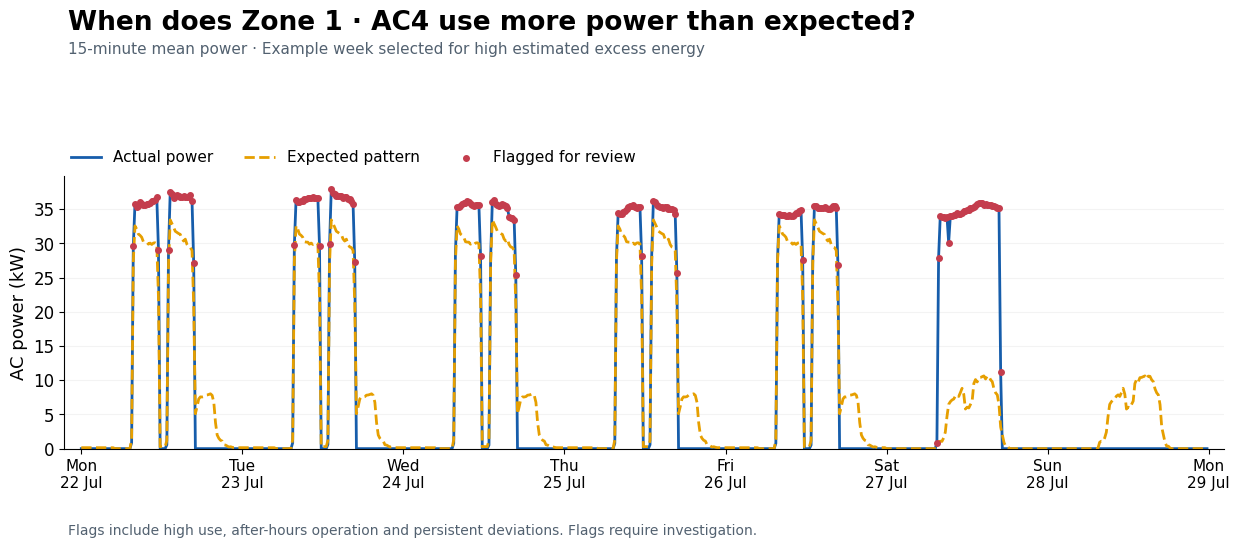

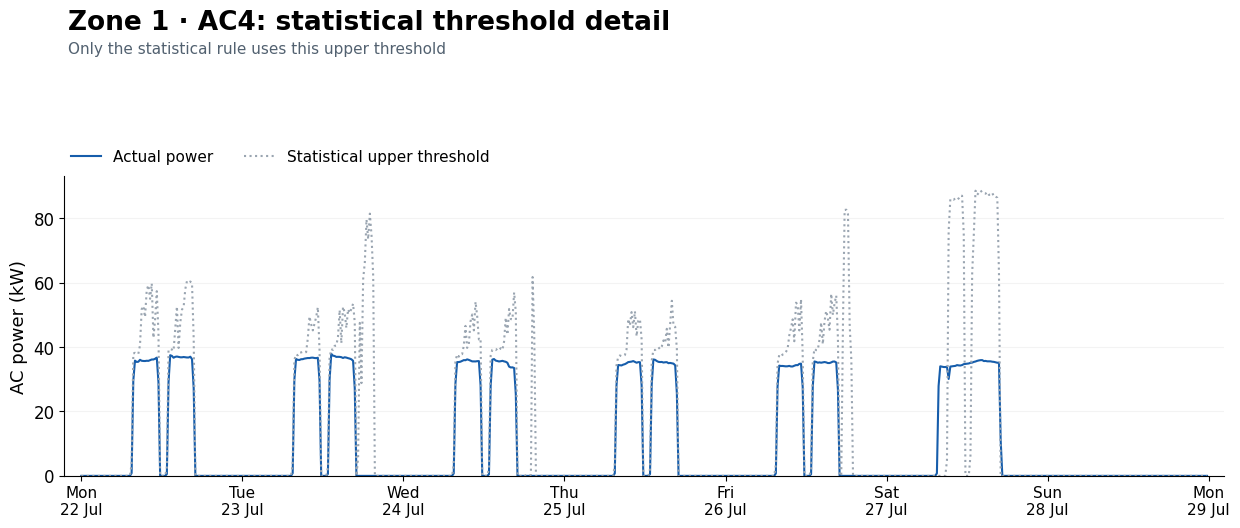

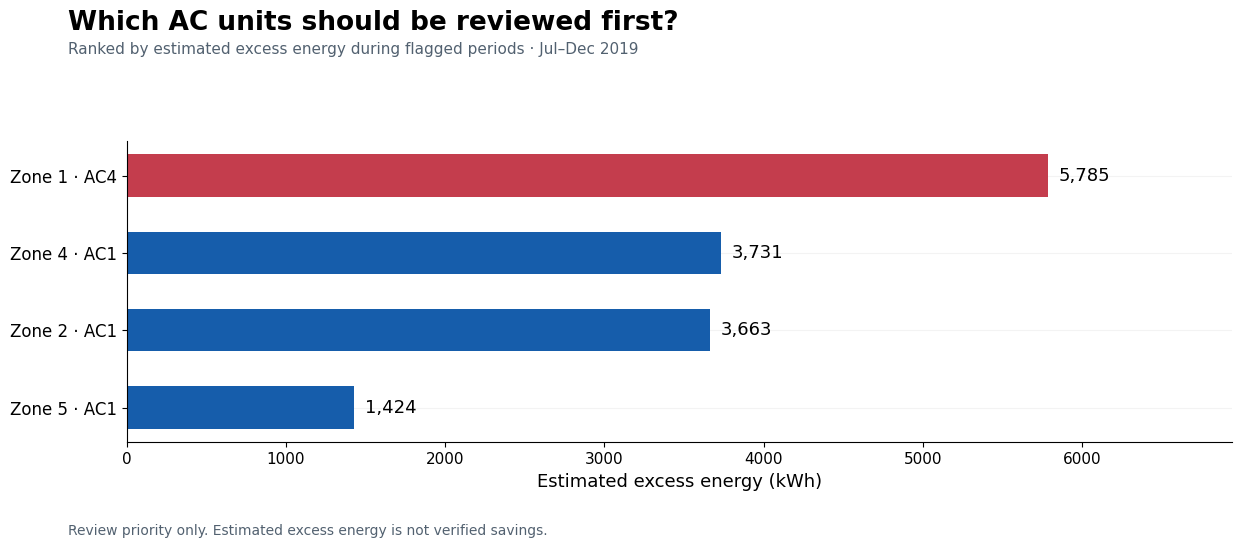

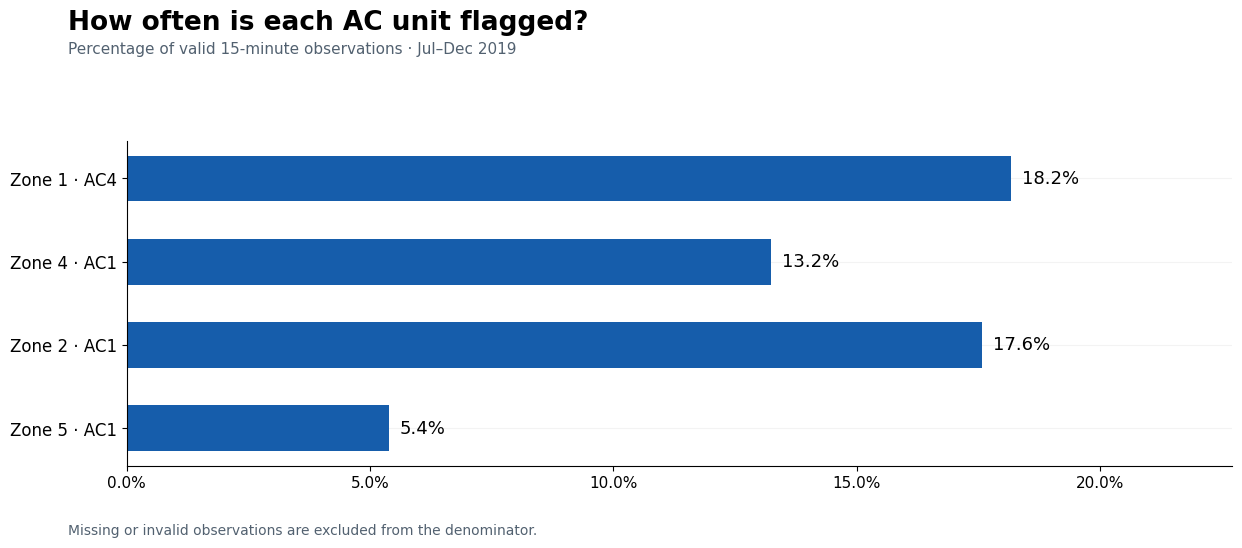

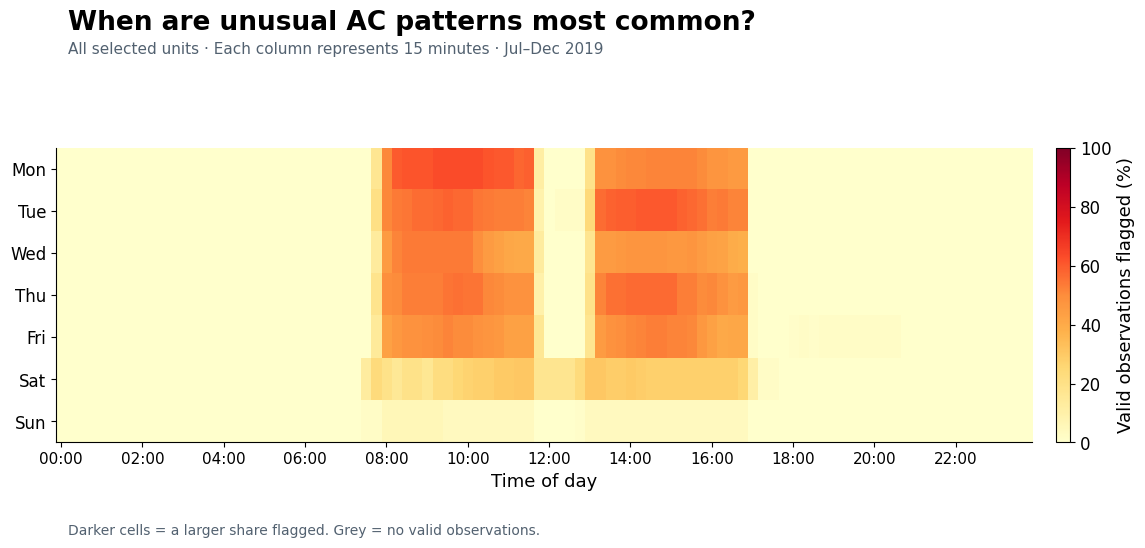

valid_reporting_intervals                    17627.000
valid_reporting_hours                         4406.750
estimated_energy_kWh_valid_intervals         98351.016
estimated_after_hours_kWh_valid_intervals     6141.814
after_hours_energy_pct_valid_intervals           6.245
15min_peak_kW                                  121.125
load_factor                                      0.184
dtype: float64

In [6]:
def calendar_matrix(index):
    # 48 hour-by-weekend groups implement hour × weekend interaction
    labels = index.hour + 24*(index.dayofweek >= 5).astype(int)
    return pd.DataFrame(np.eye(48)[labels], index=index,
                        columns=[f"hour_weekend_{i}" for i in range(48)])

def persistent_mask(flag, minimum=Q1_PERSISTENCE_INTERVALS):
    groups = flag.ne(flag.shift()).cumsum()
    lengths = flag.groupby(groups).transform("size")
    return flag & lengths.ge(minimum)

q1_calendar_group = (q1_slot + 96*(anomaly_15min.index.dayofweek >= 5).astype(int)).rename("slot_weekend")
records = []
event_rows = []
threshold_rows = []
for c in active_units:
    y = anomaly_15min[c]
    fit_mask = q1_training_mask & y.notna()
    if fit_mask.sum() < 672:
        raise ValueError(f"Too few baseline 15-minute intervals for {c}")
    # Group means equal a categorical regression baseline; unseen slots remain missing.
    expected_profile = y.loc[fit_mask].groupby(q1_calendar_group.loc[fit_mask]).mean()
    expected = q1_calendar_group.map(expected_profile).clip(lower=0)
    residual = y - expected
    train_residual = residual.loc[fit_mask]
    q1r, q3r = train_residual.quantile([.25, .75])
    residual_limit = q3r + 1.5*(q3r-q1r)
    q = y.loc[fit_mask].groupby(q1_slot_week.loc[fit_mask]).quantile([.25, .75]).unstack()
    count = y.loc[fit_mask].groupby(q1_slot_week.loc[fit_mask]).count()
    statistical_limits = (q[.75]+1.5*(q[.75]-q[.25])).where(count >= 8)
    upper = q1_slot_week.map(statistical_limits)
    iqr_q1 = q1_slot_week.map(q[.25].where(count >= 8))
    iqr_q3 = q1_slot_week.map(q[.75].where(count >= 8))
    threshold_rows.append({"unit": c, "residual_q1_kW": q1r, "residual_q3_kW": q3r,
                           "residual_limit_kW": residual_limit})
    mapped_schedule = q1_slot_week.map(schedule_table[c])
    schedule_known = mapped_schedule.notna()
    on_schedule = mapped_schedule.eq(True)
    eligible = q1_report_mask & y.notna() & expected.notna()
    statistical = eligible & y.gt(upper) & y.gt(ON_THRESHOLD_KW)
    after_hours = eligible & schedule_known & ~on_schedule & y.gt(ON_THRESHOLD_KW)
    persistent = persistent_mask(eligible & residual.gt(residual_limit) & y.gt(ON_THRESHOLD_KW))
    flagged = statistical | after_hours | persistent
    unit_table = pd.DataFrame({"Date": y.index, "unit": c, "actual_kW": y.values,
                              "expected_kW": expected.values, "IQR_upper_kW": upper.values,
                              "eligible": eligible, "statistical": statistical,
                              "after_hours": after_hours, "persistent_residual": persistent,
                              "flagged": flagged, "excess_kWh_est": residual.clip(lower=0)*Q1_INTERVAL_HOURS,
                              "observed_minutes": q1_observed_counts[c],
                              "imputed_minutes": imputed_minutes[c],
                              "has_interpolation": imputed_minutes[c].gt(0),
                              # extra columns let the dashboard re-run the rules with other thresholds
                              "IQR_q1_kW": iqr_q1.values, "IQR_q3_kW": iqr_q3.values,
                              "residual_kW": residual.values, "schedule_on": mapped_schedule.values,
                              # weather and comfort context for triage (not used by the flagging rules)
                              "outdoor_temp_C": weather_15min["outdoor_temp_C"].reindex(y.index).values,
                              "outdoor_rh_pct": weather_15min["outdoor_rh_pct"].reindex(y.index).values,
                              "rain_mm": weather_15min["rain_mm"].reindex(y.index).values,
                              "hot_day": weather_15min["hot_day"].reindex(y.index, fill_value=False).values,
                              "indoor_temp_C": indoor_series(indoor_15min, c, "temp").reindex(y.index).values,
                              "indoor_rh_pct": indoor_series(indoor_15min, c, "rh").reindex(y.index).values})
    records.append(unit_table.loc[q1_report_mask].reset_index(drop=True))
    # full regular 15-minute index prevents events crossing missing or unflagged intervals
    group_ids = flagged.ne(flagged.shift()).cumsum()
    for _, block in unit_table.loc[flagged].groupby(group_ids.loc[flagged].values):
        event_rows.append({"unit": c, "start": block["Date"].min(),
                           "end_exclusive": block["Date"].max()+pd.Timedelta(minutes=15),
                           "duration_hours": len(block)*Q1_INTERVAL_HOURS, "peak_kW": block["actual_kW"].max(),
                           "excess_kWh_est": block["excess_kWh_est"].sum(),
                           "after_hours_hours": block["after_hours"].sum()*Q1_INTERVAL_HOURS,
                           "has_statistical_flag": bool(block["statistical"].any()),
                           "has_persistent_flag": bool(block["persistent_residual"].any()),
                           "mean_outdoor_temp_C": block["outdoor_temp_C"].mean(),
                           "mean_indoor_temp_C": block["indoor_temp_C"].mean(),
                           "on_hot_day": bool(block["hot_day"].any())})

anomaly_detail = pd.concat(records, ignore_index=True)
events = pd.DataFrame(event_rows, columns=["unit", "start", "end_exclusive", "duration_hours",
    "peak_kW", "excess_kWh_est", "after_hours_hours", "has_statistical_flag", "has_persistent_flag",
    "mean_outdoor_temp_C", "mean_indoor_temp_C", "on_hot_day"])
events = events.sort_values("excess_kWh_est", ascending=False)
ranking = anomaly_detail.groupby("unit").agg(valid_intervals=("eligible","sum"),
                                            flagged_intervals=("flagged","sum"),
                                            after_hours_flagged_intervals=("after_hours","sum"))
ranking["flagged_pct"] = 100*ranking["flagged_intervals"]/ranking["valid_intervals"].replace(0,np.nan)
for column in ["valid", "flagged", "after_hours_flagged"]:
    ranking[column+"_hours"] = ranking[column+"_intervals"]*Q1_INTERVAL_HOURS
ranking["events"] = events.groupby("unit").size().reindex(ranking.index, fill_value=0)
ranking["longest_event_hours"] = events.groupby("unit")["duration_hours"].max().reindex(ranking.index, fill_value=0)
ranking["flagged_excess_kWh_est"] = anomaly_detail.loc[anomaly_detail["flagged"]].groupby("unit")["excess_kWh_est"].sum().reindex(ranking.index,fill_value=0)
ranking["events_on_hot_days"] = events.loc[events["on_hot_day"]].groupby("unit").size().reindex(ranking.index, fill_value=0)
ranking = ranking.sort_values("flagged_excess_kWh_est", ascending=False)
pd.DataFrame(threshold_rows).set_index("unit").to_csv(OUT/"anomaly_unit_thresholds.csv")
for name, table in [("anomaly_15min_detail.csv", anomaly_detail), ("anomaly_events.csv", events)]:
    table.to_csv(OUT/name,index=False)
ranking.to_csv(OUT/"anomaly_unit_ranking.csv")
display(ranking.round(2))
display(events.head(10).round(2))

# Illustration: highest-excess unit and its highest-excess reporting week
selected_unit = ranking.index[0]
unit_data = anomaly_detail.loc[anomaly_detail["unit"].eq(selected_unit)].set_index("Date")
weekly_excess = unit_data["excess_kWh_est"].where(unit_data["flagged"],0).resample("W-MON",label="left",closed="left").sum()
week_start = weekly_excess.idxmax()
view = unit_data.loc[(unit_data.index >= week_start) & (unit_data.index < week_start+pd.Timedelta(days=7))]
plot_anomaly(view, selected_unit)
plot_ranking(ranking)

anomaly_detail["slot_of_day"] = anomaly_detail["Date"].dt.hour*4 + anomaly_detail["Date"].dt.minute//15
anomaly_detail["day_of_week"] = anomaly_detail["Date"].dt.dayofweek
hourday = anomaly_detail.groupby(["day_of_week","slot_of_day"]).agg(flagged=("flagged","sum"), valid=("eligible","sum"))
hourday["flagged_pct"] = 100*hourday["flagged"]/hourday["valid"].replace(0,np.nan)
hourday.to_csv(OUT/"anomaly_15min_day_breakdown.csv")
heat = hourday["flagged_pct"].unstack().reindex(index=range(7),columns=range(96))
plot_heatmap(heat)

# Q1 floor KPIs at 15-minute resolution; Q2 floor_demand remains hourly.
q1_floor_demand = anomaly_15min.sum(axis=1, min_count=len(active_units))
floor_profile = q1_floor_demand.loc[q1_training_mask].groupby(q1_slot_week.loc[q1_training_mask]).median()
floor_expected_schedule = q1_slot_week.map(floor_profile)
report_floor = q1_floor_demand.loc[q1_report_mask].dropna()
schedule_values = floor_expected_schedule.reindex(report_floor.index)
ah = schedule_values.notna() & schedule_values.le(ON_THRESHOLD_KW)
energy = report_floor.sum()*Q1_INTERVAL_HOURS
ah_energy = report_floor.loc[ah].sum()*Q1_INTERVAL_HOURS
floor_kpis = pd.Series({"valid_reporting_intervals": len(report_floor),
    "valid_reporting_hours": len(report_floor)*Q1_INTERVAL_HOURS,
    "estimated_energy_kWh_valid_intervals": energy,
    "estimated_after_hours_kWh_valid_intervals": ah_energy,
    "after_hours_energy_pct_valid_intervals": 100*ah_energy/energy if energy else np.nan,
    "15min_peak_kW": report_floor.max(), "load_factor": report_floor.mean()/report_floor.max()})
floor_kpis.to_csv(OUT/"floor_reporting_15min_kpis.csv",header=["value"])
display(floor_kpis.round(3))


## 3b. Weather sensitivity, comfort and setpoint inputs
**Question:** how much does each unit's power depend on outdoor temperature, and are zones kept within the comfort band?

For each unit, a baseline-only linear regression fits hourly power (hours when the unit is running, weekdays) on outdoor temperature, outdoor RH and hour-of-day dummies. The temperature coefficient (kW per °C) is used by the dashboard's **setpoint simulator** as a proxy for the kW change per 1 °C setpoint change. Raising the indoor setpoint by 1 °C narrows the indoor–outdoor temperature difference about as much as a day that is 1 °C cooler. This is an approximation: it ignores latent load and part-load efficiency, and it must be confirmed by a measured trial before any savings are claimed.

Comfort KPI = share of operating hours with indoor temperature inside the comfort band (and RH inside the proposal's 40–60 % band).

,fit_hours,R2,kW_per_degC_outdoor,mean_running_kW,pct_per_degC,median_indoor_temp_C_running,pct_running_hours_in_comfort_band,pct_running_hours_in_RH_band
unit,,,,,,,,
F7_z1_AC4(kW),2303,0.80,1.37,28.28,4.84,19.31,8.07,5.35
F7_z2_AC1(kW),2365,0.92,0.40,21.87,1.82,21.77,20.02,10.76
F7_z4_AC1(kW),2105,0.85,1.16,22.28,5.19,20.72,6.83,33.27
F7_z5_AC1(kW),2053,0.63,1.01,9.28,10.89,21.48,13.22,38.51


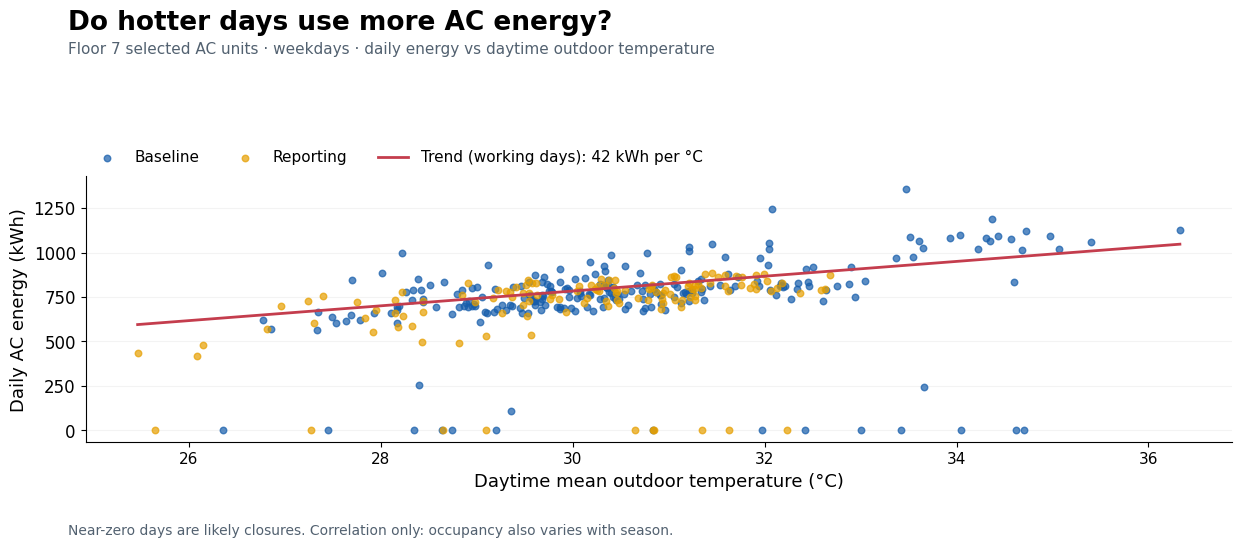

In [7]:
sensitivity_rows = []
for c in active_units:
    frame = pd.DataFrame({"kW": observed_hourly[c],
                          "outdoor_temp_C": weather_hourly["outdoor_temp_C"].reindex(observed_hourly.index),
                          "outdoor_rh_pct": weather_hourly["outdoor_rh_pct"].reindex(observed_hourly.index),
                          "indoor_temp_C": indoor_series(indoor_hourly, c, "temp").reindex(observed_hourly.index),
                          "indoor_rh_pct": indoor_series(indoor_hourly, c, "rh").reindex(observed_hourly.index)})
    running = frame["kW"].gt(ON_THRESHOLD_KW) & (frame.index.dayofweek < 5) & ~frame.index.normalize().isin(verified_dates)
    fit = frame.loc[running & (frame.index < TEST_START)].dropna(subset=["kW", "outdoor_temp_C", "outdoor_rh_pct"])
    x = pd.concat([fit[["outdoor_temp_C", "outdoor_rh_pct"]],
                   pd.get_dummies(fit.index.hour, prefix="h", drop_first=True).set_axis(fit.index).astype(float)], axis=1)
    model = LinearRegression().fit(x, fit["kW"])
    slope = model.coef_[0]
    report = frame.loc[running & (frame.index >= TEST_START)]
    in_band = report["indoor_temp_C"].between(*COMFORT_BAND_C).where(report["indoor_temp_C"].notna())
    rh_band = report["indoor_rh_pct"].between(*RH_BAND_PCT).where(report["indoor_rh_pct"].notna())
    sensitivity_rows.append({"unit": c, "fit_hours": len(fit), "R2": model.score(x, fit["kW"]),
                             "kW_per_degC_outdoor": slope,
                             "mean_running_kW": fit["kW"].mean(),
                             "pct_per_degC": 100*slope/fit["kW"].mean(),
                             "median_indoor_temp_C_running": report["indoor_temp_C"].median(),
                             "pct_running_hours_in_comfort_band": 100*in_band.mean(),
                             "pct_running_hours_in_RH_band": 100*rh_band.mean()})
setpoint_sensitivity = pd.DataFrame(sensitivity_rows).set_index("unit")
setpoint_sensitivity.to_csv(OUT / "setpoint_sensitivity.csv")
display(setpoint_sensitivity.round(2))

# Daily floor AC energy against daytime outdoor temperature (weekdays only)
daily = pd.DataFrame({"kWh": floor_demand.resample("D").sum(min_count=24), "temp": daytime_temp}).dropna()
daily = daily.loc[daily.index.dayofweek < 5]
daily["period"] = np.where(daily.index < TEST_START, "Baseline", "Reporting")
fig, ax = clear_figure("Do hotter days use more AC energy?",
                       "Floor 7 selected AC units · weekdays · daily energy vs daytime outdoor temperature")
for period, colour in [("Baseline", BLUE), ("Reporting", ORANGE)]:
    part = daily.loc[daily["period"].eq(period)]
    ax.scatter(part["temp"], part["kWh"], s=22, alpha=.7, color=colour, label=period)
active_days = daily.loc[daily["kWh"] > daily["kWh"].quantile(.2)]
trend = np.polyfit(active_days["temp"], active_days["kWh"], 1)
xs = np.linspace(daily["temp"].min(), daily["temp"].max(), 20)
ax.plot(xs, np.polyval(trend, xs), color=RED, linewidth=2, label=f"Trend (working days): {trend[0]:.0f} kWh per °C")
ax.set_xlabel("Daytime mean outdoor temperature (°C)"); ax.set_ylabel("Daily AC energy (kWh)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3, frameon=False, borderaxespad=0)
finish_clear(fig, "05b_energy_vs_outdoor_temperature.png",
             "Near-zero days are likely closures. Correlation only: occupancy also varies with season.")


## 4. RQ2 — forecasting model comparison
Forecasts are issued at **00:00 for that day's next 24 hourly intervals**. For a target at hour `t`, `t−24` and `t−168` are available before that issue time, assuming immediate hourly-data delivery. No lag-1 is used: it would leak same-day actual readings into a day-ahead forecast.

Models: yesterday, last week, hour-of-week median, hour × weekend regression, regression with lag-24/168, and Random Forest with calendar and lag features. **M5/M6** add Open-Meteo outdoor temperature, RH and rain for the target hour. Observed weather stands in for a day-ahead weather forecast, so M5/M6 test errors are optimistic. In operation, use the [Open-Meteo forecast API](https://open-meteo.com/en/docs) at issue time. Earlier reporting-day measurements can supply subsequent days' lags; the parameters remain fixed through the six-month test. This is rolling day-ahead evaluation, not a single six-month forecast.

Selection: train July–March, validate April–June; choose lowest validation MAE on common valid hours. Refit on July 2018–June 2019, then score July–December once. Missing lags remain missing. All model comparisons use identical timestamps; per-model coverage is exported separately.

NMBE here = 100 × mean(predicted−actual) / mean(actual); positive means overprediction. CV(RMSE) = 100 × RMSE / mean(actual). These out-of-sample normalised metrics use `n`, without calibration parameter-count adjustments. The ±10%/30% guide thresholds are shown as requested, not a claim of formal standards compliance.


Validation-selected model: M1 median profile


,hours,MAE_kW,RMSE_kW,NMBE_pct,CV_RMSE_pct,peak_hour_MAE_kW,guide_NMBE_pass,guide_CV_RMSE_pass
model,,,,,,,,
M1 median profile,2178,10.001,22.529,-17.509,85.250,16.230,False,False
M4 Random Forest,2178,10.475,22.832,3.184,86.393,12.690,True,False
M3 regression with lags,2178,10.756,21.021,-13.125,79.543,19.475,False,False
M6 Random Forest + weather,2178,11.228,23.761,6.984,89.912,12.989,True,False
M2 calendar regression,2178,11.294,21.836,-15.882,82.625,20.728,False,False
M0 last week,2178,11.681,28.650,-1.212,108.409,19.079,True,False
M5 regression + weather,2178,11.917,20.856,-3.115,78.920,16.914,True,False
M0 yesterday,2178,15.130,34.996,0.405,132.422,32.132,True,False


Refitting on full baseline and predicting reporting days...
Test comparison (common valid hours):


,hours,MAE_kW,RMSE_kW,NMBE_pct,CV_RMSE_pct,peak_hour_MAE_kW,guide_NMBE_pass,guide_CV_RMSE_pass
model,,,,,,,,
M1 median profile,4383,5.606,17.060,1.512,76.297,9.106,True,False
M6 Random Forest + weather,4383,6.477,15.971,3.653,71.425,12.733,True,False
M4 Random Forest,4383,6.846,16.491,3.236,73.752,14.767,True,False
M5 regression + weather,4383,6.951,15.499,3.965,69.314,13.886,True,False
M3 regression with lags,4383,7.166,15.782,5.257,70.580,14.000,True,False
M0 last week,4383,7.561,21.372,2.395,95.582,19.025,True,False
M2 calendar regression,4383,7.635,16.449,5.838,73.564,14.095,True,False
M0 yesterday,4383,11.406,29.784,0.306,133.203,32.158,True,False


Sensitivity only: exclude unverified suspected closure dates


,hours,MAE_kW,RMSE_kW,NMBE_pct,CV_RMSE_pct,peak_hour_MAE_kW,guide_NMBE_pass,guide_CV_RMSE_pass
model,,,,,,,,
M1 median profile,4143,4.103,11.933,-6.214,50.445,9.106,True,False
M6 Random Forest + weather,4143,5.236,11.957,-3.182,50.545,12.733,True,False
M4 Random Forest,4143,5.564,12.364,-3.857,52.269,14.767,True,False
M5 regression + weather,4143,5.701,11.301,-3.024,47.775,13.886,True,False
M3 regression with lags,4143,5.889,11.516,-1.898,48.684,14.000,True,False
M0 last week,4143,6.116,17.468,-5.563,73.844,19.025,True,False
M2 calendar regression,4143,6.270,11.829,-1.803,50.007,14.095,True,False
M0 yesterday,4143,11.441,29.750,-2.339,125.765,32.158,True,False


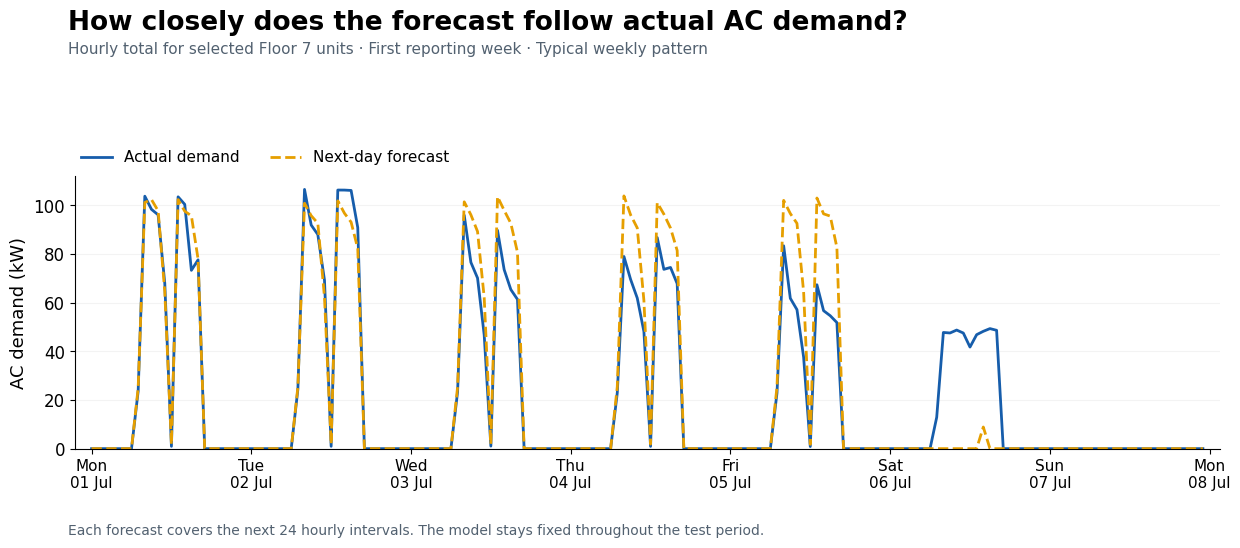

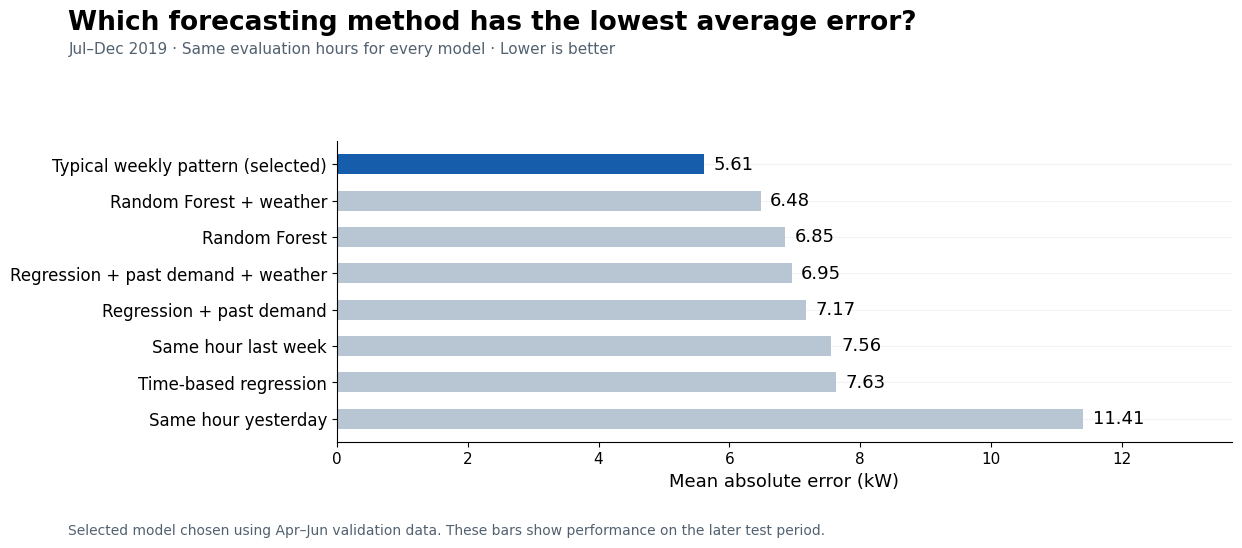

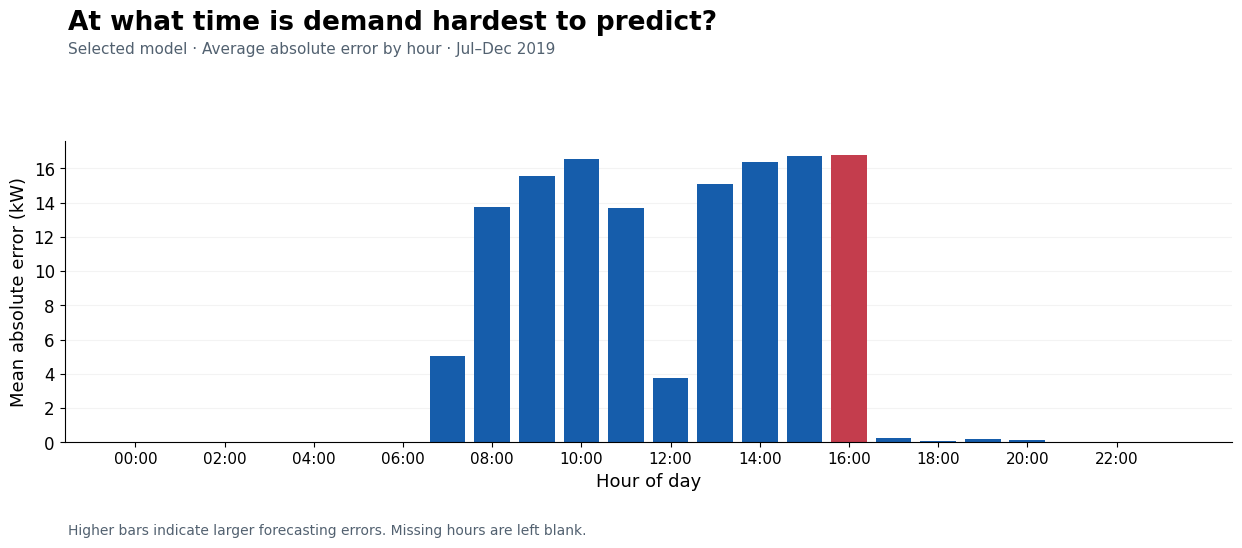

Top observed test peaks (common valid hours):


,actual,M1 median profile,absolute_error_kW
Date,,,
2019-10-28 14:00:00,115.12,97.58,17.54
2019-07-22 14:00:00,115.08,97.58,17.50
2019-10-24 14:00:00,114.96,96.37,18.59
2019-08-15 14:00:00,114.91,96.37,18.54
2019-10-25 14:00:00,114.77,96.49,18.27
2019-07-30 14:00:00,114.70,96.75,17.96
2019-07-18 08:00:00,114.70,103.86,10.84
2019-07-18 14:00:00,114.38,96.37,18.01
2019-07-23 14:00:00,114.06,96.75,17.31


In [8]:
WEATHER_FEATURES = ["outdoor_temp_C", "outdoor_rh_pct", "rain_mm"]

def forecasting_features(index, history, weather=None):
    result = pd.DataFrame({"hour":index.hour, "day_of_week":index.dayofweek,
                           "weekend":(index.dayofweek>=5).astype(int)},index=index)
    # Exact timestamp lookup, so missing observations do not compress time
    result["lag24"] = history.reindex(index-pd.Timedelta(hours=24)).to_numpy()
    result["lag168"] = history.reindex(index-pd.Timedelta(hours=168)).to_numpy()
    if weather is not None:
        # Weather for the target hour: observed values stand in for a day-ahead weather forecast
        for column in WEATHER_FEATURES:
            result[column] = weather[column].reindex(index).to_numpy()
    return result

def make_predictions(history, fit_index, predict_index, weather=None):
    fit_y = history.reindex(fit_index).dropna()
    fit_index = fit_y.index
    fit_x = forecasting_features(fit_index,history,weather)
    predict_x = forecasting_features(predict_index,history,weather)
    result = pd.DataFrame(index=predict_index)
    result["M0 yesterday"] = predict_x["lag24"]
    result["M0 last week"] = predict_x["lag168"]
    fit_how = fit_index.dayofweek*24+fit_index.hour
    medians = fit_y.groupby(fit_how).median()
    result["M1 median profile"] = pd.Series(predict_index.dayofweek*24+predict_index.hour,index=predict_index).map(medians)
    calendar_fit = calendar_matrix(fit_index)
    calendar_predict = calendar_matrix(predict_index)
    model = LinearRegression(fit_intercept=False).fit(calendar_fit,fit_y)
    result["M2 calendar regression"] = np.maximum(0,model.predict(calendar_predict))
    lag_valid = fit_x[["lag24","lag168"]].notna().all(axis=1)
    pred_valid = predict_x[["lag24","lag168"]].notna().all(axis=1)
    if lag_valid.sum() < 168:
        raise ValueError("Not enough valid lagged training hours. Extend the baseline or inspect gaps.")
    reg_x = pd.concat([calendar_fit,fit_x[["lag24","lag168"]]],axis=1)
    reg_predict = pd.concat([calendar_predict,predict_x[["lag24","lag168"]]],axis=1)
    lag_model = LinearRegression(fit_intercept=False).fit(reg_x.loc[lag_valid],fit_y.loc[lag_valid])
    result["M3 regression with lags"] = np.nan
    result.loc[pred_valid,"M3 regression with lags"] = np.maximum(0,lag_model.predict(reg_predict.loc[pred_valid]))
    forest = RandomForestRegressor(n_estimators=150,min_samples_leaf=8,random_state=42,n_jobs=-1)
    forest.fit(fit_x.loc[lag_valid,["hour","day_of_week","weekend","lag24","lag168"]],fit_y.loc[lag_valid])
    result["M4 Random Forest"] = np.nan
    base_features = ["hour","day_of_week","weekend","lag24","lag168"]
    result.loc[pred_valid,"M4 Random Forest"] = np.maximum(0,forest.predict(predict_x.loc[pred_valid,base_features]))
    if weather is not None:
        weather_fit = lag_valid & fit_x[WEATHER_FEATURES].notna().all(axis=1)
        weather_pred = pred_valid & predict_x[WEATHER_FEATURES].notna().all(axis=1)
        wx = pd.concat([calendar_fit,fit_x[["lag24","lag168"]+WEATHER_FEATURES]],axis=1)
        wx_predict = pd.concat([calendar_predict,predict_x[["lag24","lag168"]+WEATHER_FEATURES]],axis=1)
        weather_model = LinearRegression(fit_intercept=False).fit(wx.loc[weather_fit],fit_y.loc[weather_fit])
        weather_forest = RandomForestRegressor(n_estimators=150,min_samples_leaf=8,random_state=42,n_jobs=-1)
        weather_forest.fit(fit_x.loc[weather_fit],fit_y.loc[weather_fit])
        result["M5 regression + weather"] = np.nan
        result["M6 Random Forest + weather"] = np.nan
        if weather_pred.any():
            result.loc[weather_pred,"M5 regression + weather"] = np.maximum(0,weather_model.predict(wx_predict.loc[weather_pred]))
            result.loc[weather_pred,"M6 Random Forest + weather"] = np.maximum(0,weather_forest.predict(predict_x.loc[weather_pred]))
    return result

def metrics_table(actual,predictions,peak_threshold):
    common = pd.concat([actual.rename("actual"),predictions],axis=1).dropna()
    if common.empty:
        raise ValueError("No common valid hours for evaluation. Check dates and gaps.")
    rows=[]
    for c in predictions:
        error=common[c]-common["actual"]
        mean_actual=common["actual"].mean()
        peak=common["actual"] >= peak_threshold
        rows.append({"model":c,"hours":len(common),"MAE_kW":error.abs().mean(),
                     "RMSE_kW":np.sqrt(np.mean(error**2)),
                     "NMBE_pct":100*error.mean()/mean_actual,
                     "CV_RMSE_pct":100*np.sqrt(np.mean(error**2))/mean_actual,
                     "peak_hour_MAE_kW":error.loc[peak].abs().mean()})
    table=pd.DataFrame(rows).set_index("model").sort_values("MAE_kW")
    table["guide_NMBE_pass"]=table["NMBE_pct"].abs().le(10)
    table["guide_CV_RMSE_pass"]=table["CV_RMSE_pct"].le(30)
    return table,common

history = floor_demand
fit_early = history.index[(history.index < VALIDATION_START) & ~verified_mask]
validation_index = history.index[(history.index >= VALIDATION_START) & (history.index < TEST_START) & ~verified_mask]
validation_predictions = make_predictions(history,fit_early,validation_index,weather_hourly)
validation_metrics,_ = metrics_table(history.reindex(validation_index),validation_predictions,
                                      history.reindex(fit_early).quantile(.9))
selected_model = validation_metrics.index[0]
print("Validation-selected model:",selected_model)
display(validation_metrics.round(3))
validation_metrics.to_csv(OUT/"forecast_validation_metrics.csv")

full_fit = history.index[training_mask]
test_index = history.index[report_mask]
print("Refitting on full baseline and predicting reporting days...",flush=True)
test_predictions = make_predictions(history,full_fit,test_index,weather_hourly)
peak_threshold = history.reindex(full_fit).quantile(.9)
test_metrics, common_test = metrics_table(history.reindex(test_index),test_predictions,peak_threshold)
test_metrics.to_csv(OUT/"forecast_test_metrics.csv")
forecast_table = pd.concat([history.reindex(test_index),test_predictions],axis=1)
forecast_table.index.name="Date"
forecast_table.to_csv(OUT/"forecast_hourly_actual_predictions.csv")
coverage = pd.DataFrame({"predicted_hours":test_predictions.notna().sum(),
                        "scorable_hours":test_predictions.where(history.reindex(test_index).notna(),axis=0).notna().sum()})
coverage.to_csv(OUT/"forecast_model_coverage.csv")
print("Test comparison (common valid hours):")
display(test_metrics.round(3))

# Sensitivity only: suspected closures identified from outcomes, NOT known at forecast issue time
suspected_dates = suspected.index
sensitivity_index = common_test.index[~common_test.index.normalize().isin(suspected_dates)]
sensitivity_metrics,_ = metrics_table(history.reindex(sensitivity_index),test_predictions.reindex(sensitivity_index),peak_threshold)
sensitivity_metrics.to_csv(OUT/"forecast_sensitivity_excluding_suspected_closures.csv")
print("Sensitivity only: exclude unverified suspected closure dates")
display(sensitivity_metrics.round(3))

# Fixed illustrative test week, not selected for low forecast errors
forecast_week_start = TEST_START
forecast_week_end = TEST_START+pd.Timedelta(days=7)
view = forecast_table.loc[(forecast_table.index>=forecast_week_start)&(forecast_table.index<forecast_week_end)]
plot_forecast(view, selected_model)
plot_accuracy(test_metrics, selected_model)

selected_errors = (common_test[selected_model]-common_test["actual"]).abs()
error_by_hour = selected_errors.groupby(selected_errors.index.hour).mean()
error_by_hour.to_csv(OUT/"selected_model_MAE_by_hour.csv",header=["MAE_kW"])
plot_hour_error(error_by_hour)
peak_hours = common_test.loc[common_test["actual"]>=peak_threshold,["actual",selected_model]].copy()
peak_hours["absolute_error_kW"]=(peak_hours[selected_model]-peak_hours["actual"]).abs()
peak_hours.sort_values("actual",ascending=False).to_csv(OUT/"peak_demand_hours.csv")
print("Top observed test peaks (common valid hours):")
display(peak_hours.sort_values("actual",ascending=False).head(10).round(2))


## 5. A genuine next-24-hour forecast after the dataset ends
This is a historical demonstration for the day after the last observation, **not a forecast for today**. Fit the selected method on all valid history available at the new issue time. Missing-lag hours use an explicitly labelled median-profile fallback. The fallback was not included in the primary six-model test comparison; evaluate that hybrid separately before deployment. No prediction intervals are claimed.

The example is for 1 January 2020. No holiday-calendar input is supplied, so the routine-day forecast can overpredict a closure day. Verify holidays before using this operationally.


,predicted_kW,method,outdoor_temp_C,outdoor_rh_pct,rain_mm,issue_time
Date,,,,,,
2020-01-01 00:00:00,0.00,M1 median profile,27.05,62.5,0.0,2020-01-01
2020-01-01 01:00:00,0.00,M1 median profile,26.65,63.0,0.0,2020-01-01
2020-01-01 02:00:00,0.00,M1 median profile,26.35,63.5,0.0,2020-01-01
2020-01-01 03:00:00,0.00,M1 median profile,25.95,65.5,0.0,2020-01-01
2020-01-01 04:00:00,0.00,M1 median profile,25.40,68.5,0.0,2020-01-01
2020-01-01 05:00:00,0.00,M1 median profile,24.90,70.5,0.0,2020-01-01
2020-01-01 06:00:00,0.00,M1 median profile,24.70,73.0,0.0,2020-01-01
2020-01-01 07:00:00,23.96,M1 median profile,25.65,71.0,0.0,2020-01-01
2020-01-01 08:00:00,101.01,M1 median profile,27.45,63.5,0.0,2020-01-01


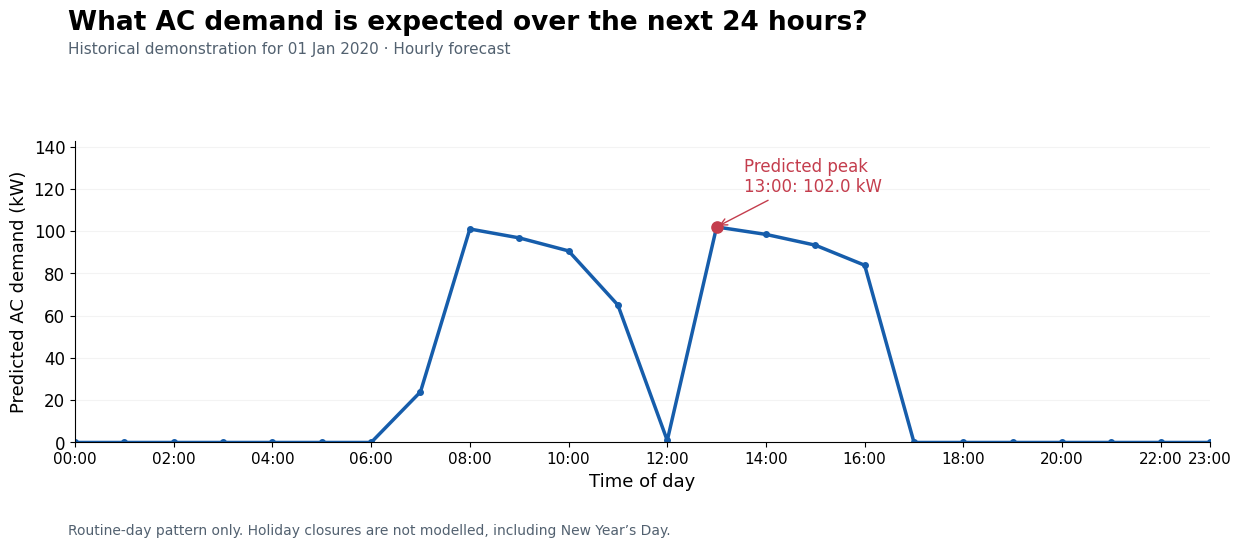

Predicted peak: 2020-01-01 13:00:00 101.98 kW
Predicted daily AC energy: 756.04 kWh (24 one-hour predictions)


In [9]:
last_valid = history.last_valid_index()
issue_time = last_valid.normalize()+pd.Timedelta(days=1)
future_index = pd.date_range(issue_time,periods=24,freq="h")
# Only readings whose hourly interval has completed by the forecast issue time
available_history = history.loc[history.index+pd.Timedelta(hours=1) <= issue_time]
future_predictions = make_predictions(available_history,available_history.index,future_index,weather_hourly)
next24 = pd.DataFrame({"predicted_kW":future_predictions[selected_model],
                       "method":selected_model},index=future_index)
fallback = next24["predicted_kW"].isna()
next24.loc[fallback,"predicted_kW"] = future_predictions.loc[fallback,"M1 median profile"]
next24.loc[fallback,"method"] = "M1 median profile (missing-lag fallback)"
next24 = next24.join(weather_hourly.reindex(future_index)[["outdoor_temp_C","outdoor_rh_pct","rain_mm"]])
next24.index.name="Date"
next24["issue_time"] = issue_time
next24.to_csv(OUT/"next_24_hours_forecast.csv")
display(next24.round(2))
plot_nextday(next24, issue_time)
print("Predicted peak:",next24["predicted_kW"].idxmax(),round(next24["predicted_kW"].max(),2),"kW")
print("Predicted daily AC energy:",round(next24["predicted_kW"].sum(),2),"kWh (24 one-hour predictions)")


## 6. Optional peer profiles (Floors 3, 4, 5 and 7)
Run this cell if the combined CSV contains all four floors. Compare the four selected active units at the same zone/AC position only, and use each unit's own baseline weekday daytime mean for normalisation. Equal layout alone does not prove equal occupancy, capacity, or efficiency. This is contextual benchmarking; it does not decide which unit is faulty.


Reading 16 peer columns in one pass...


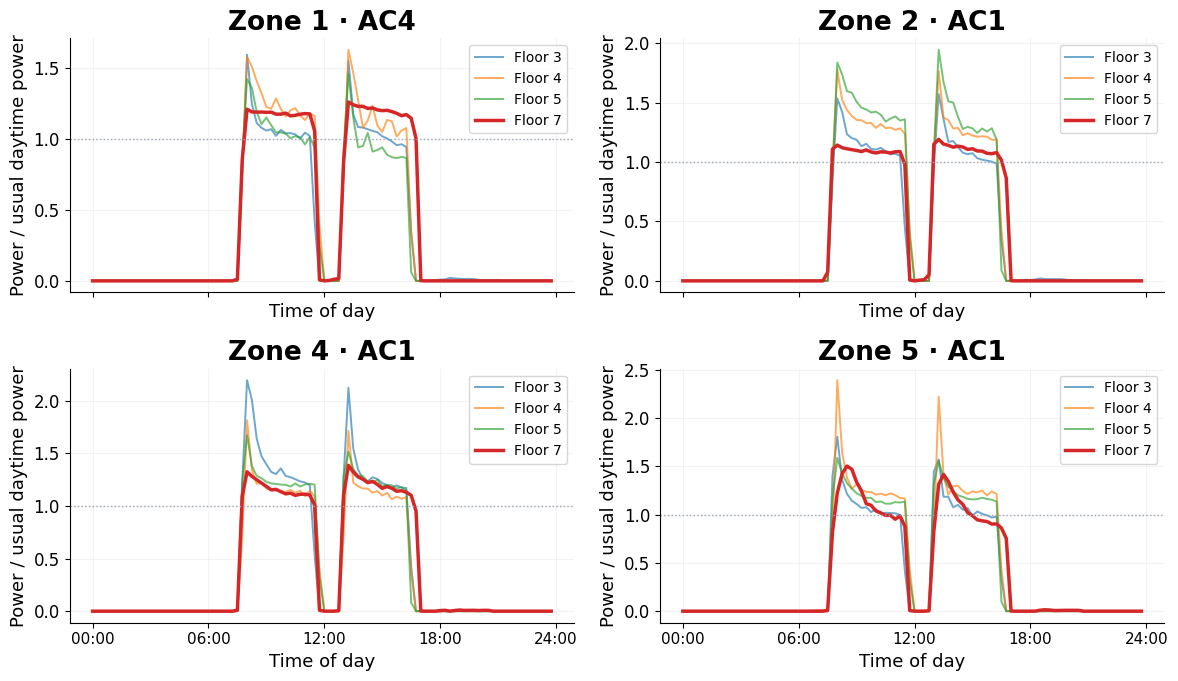

In [10]:
RUN_PEER_COMPARISON = True
if RUN_PEER_COMPARISON:
    peer_rows=[]
    peer_wanted = sorted({f"F{f}_"+c.split("_",1)[1] for f in [3,4,5,7] for c in active_units} & set(headers))
    print(f"Reading {len(peer_wanted)} peer columns in one pass...", flush=True)
    peer_all = pd.read_csv(INPUT_FILE,usecols=["Date"]+peer_wanted,low_memory=False)
    peer_all["Date"] = pd.to_datetime(peer_all["Date"],errors="coerce")
    peer_all = peer_all.dropna(subset=["Date"]).set_index("Date").sort_index()
    for peer_floor in [3,4,5,7]:
        peer_columns = [f"F{peer_floor}_"+c.split("_",1)[1] for c in active_units
                        if f"F{peer_floor}_"+c.split("_",1)[1] in headers]
        if not peer_columns:
            print(f"Skipping Floor {peer_floor}: peer columns not in this file")
            continue
        peer=peer_all[peer_columns].apply(pd.to_numeric,errors="coerce")
        peer=peer.reindex(minute_index).mask(lambda d:d.lt(0))
        for c,limit in MAX_VALID_KW.items():
            if c in peer: peer[c]=peer[c].mask(peer[c]>limit)
        ph=peer.resample(Q1_FREQ).mean().where(peer.resample(Q1_FREQ).count()>=MIN_MINUTES_PER_Q1_INTERVAL)
        norm_mask=(ph.index<TEST_START)&(ph.index.dayofweek<5)&(ph.index.hour>=8)&(ph.index.hour<17)&~ph.index.normalize().isin(verified_dates)
        means=ph.loc[norm_mask].mean().where(ph.loc[ph.index<TEST_START].mean() >= ACTIVE_MEAN_KW).replace(0,np.nan)
        normalised=ph.div(means).loc[(ph.index>=TEST_START)&(ph.index<END)&~ph.index.normalize().isin(verified_dates)]
        profile=normalised.loc[normalised.index.dayofweek<5].groupby(normalised.loc[normalised.index.dayofweek<5].index.hour*4 + normalised.loc[normalised.index.dayofweek<5].index.minute//15).mean()
        for c in peer_columns:
            position=c.split("_",1)[1].replace("(kW)","")
            for hour,value in profile[c].items():
                peer_rows.append({"floor":peer_floor,"position":position,"slot_of_day":hour,"normalised_kW":value})
        del peer,ph
    del peer_all
    peer_profiles=pd.DataFrame(peer_rows)
    if not peer_profiles.empty:
        peer_profiles.to_csv(OUT/"peer_normalised_profiles.csv",index=False)
        fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
        for position,ax in zip([c.split("_",1)[1].replace("(kW)","") for c in active_units],axes.flat):
            sub=peer_profiles.loc[peer_profiles["position"].eq(position)]
            for peer_floor,block in sub.groupby("floor"):
                ax.plot(block["slot_of_day"]/4,block["normalised_kW"],label=f"Floor {peer_floor}", linewidth=2.5 if peer_floor==FLOOR else 1.4, alpha=1 if peer_floor==FLOOR else .65)
            ax.set_title(unit_label(position)); ax.set_xlabel("Time of day"); ax.set_ylabel("Power / usual daytime power"); ax.legend(fontsize=10)
            ax.axhline(1, color=GREY, linestyle=":", linewidth=1)
            ax.set_xticks([0,6,12,18,24], ["00:00","06:00","12:00","18:00","24:00"])
        save_plot("10_peer_profiles.png")


## 7. Section 5 evidence summary
This cell writes a short results summary and a proposal-ready description to the output folder. Figures and tables are separate files suitable for slides. Flag counts are algorithm-dependent and need sponsor/FM investigation; they are not the number of faults. Estimated excess and after-hours kWh are not claimed savings. No measured intervention exists in this dataset.

Useful checks before the pitch:
- Inspect `monthly_coverage.csv` and the event detail. Check how many flagged 15-minute intervals contain filled minute values.
- Verify schedule and suspected closure dates with the facilities manager/calendar.
- Re-run with `MIN_MINUTES_PER_Q1_INTERVAL = 15` for Q1 and `MIN_MINUTES_PER_HOUR = 60` for Q2 and compare results.
- Review the monthly evening chart for schedule drift; do not introduce a post-change predictor without an independent date known at forecast time.
- Do not quote the attachment's preliminary MAEs as final: this notebook uses explicit validity and common-support rules.

Sources for implementation: [pandas resampling](https://pandas.pydata.org/docs/reference/resampling.html), [scikit-learn time-series forecasting](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html). Dataset source: [CU-BEMS paper](https://www.nature.com/articles/s41597-020-00582-3).


In [11]:
selected_result=test_metrics.loc[selected_model]
last_week_mae=test_metrics.loc["M0 last week","MAE_kW"]
improvement=100*(1-selected_result["MAE_kW"]/last_week_mae)
summary = f"""FLOOR {FLOOR} RESULTS — generated from the supplied data
Baseline: {START.date()} to {(TEST_START-pd.Timedelta(days=1)).date()}
Reporting: {TEST_START.date()} to {(END-pd.Timedelta(days=1)).date()}
Active units: {len(active_units)}
Potential anomaly review events: {len(events)}
Flagged 15-minute unit-intervals: {int(anomaly_detail['flagged'].sum())}
Flagged unit-hours: {anomaly_detail['flagged'].sum()*Q1_INTERVAL_HOURS:.2f}
Q1 resolution: 15 minutes; Q2 resolution: hourly
Highest-excess unit: {ranking.index[0]}
Forecast selected on April–June validation: {selected_model}
Common test hours: {int(selected_result['hours'])}
Selected forecast MAE: {selected_result['MAE_kW']:.3f} kW
Same-hour-last-week MAE: {last_week_mae:.3f} kW
MAE improvement vs last week: {improvement:.1f}%
Selected NMBE: {selected_result['NMBE_pct']:.2f}%
Selected CV(RMSE): {selected_result['CV_RMSE_pct']:.2f}%
Selected peak-hour MAE: {selected_result['peak_hour_MAE_kW']:.3f} kW
Suspected unverified closure weekdays: {len(suspected)}
Weather: Open-Meteo hourly, shifted GMT -> UTC+{WEATHER_UTC_OFFSET_HOURS}; hot day = daytime temp above baseline q{HOT_DAY_QUANTILE:.0%} for that month
Flagged events on hot days: {int(events['on_hot_day'].sum())} of {len(events)}
Weather-aware forecast (M5/M6) best test MAE: {test_metrics.loc[[m for m in test_metrics.index if 'weather' in m],'MAE_kW'].min():.3f} kW (uses observed weather)
Median indoor temperature while running (reporting): {setpoint_sensitivity['median_indoor_temp_C_running'].median():.1f} °C
Historical next-day demonstration: {issue_time.date()}
All anomaly labels are potential anomalies. No diagnosed faults or proven savings.
"""
print(summary)
(OUT/"results_summary.txt").write_text(summary, encoding="utf-8")
section5 = """5. Expected outputs

Output 1 — AC electricity-consumption anomaly report
The report will show 15-minute actual mean power against the expected baseline, with potential anomalies highlighted. It will include a ranked list of Floor 7 AC units based on flagged event frequency, persistence and estimated excess consumption, plus an event table showing time, duration, peak power and after-hours context. A 15-minute-slot-by-day-of-week heatmap will identify when unusual consumption occurs. Flags will support facilities-manager investigation and operating-schedule reviews; they will not be presented as confirmed equipment faults or proven energy savings.

Output 2 — Next-day AC electrical-demand forecast
The report will compare actual hourly floor demand with rolling next-day forecasts and display a 24-hour forecast issued at midnight. A comparison table will report MAE, NMBE, CV(RMSE), peak-hour error and the number of valid evaluation hours for each benchmark and model. The model will be chosen on an earlier validation period and then assessed on the July–December 2019 test period. Missing-data coverage and a separate sensitivity analysis excluding suspected closure days will be reported. The final 24-hour chart is a historical demonstration for the day following the dataset, rather than a current forecast.

Optional combined view
A facilities-management summary can place priority anomaly events beside expected peak-demand hours to support schedule reviews and demand planning. Any later energy-saving intervention will require measured before/after evidence and checks on indoor conditions.
"""
(OUT/"section_5_draft.txt").write_text(section5, encoding="utf-8")
print("Charts and CSV tables saved to:",OUT)


FLOOR 7 RESULTS — generated from the supplied data
Baseline: 2018-07-01 to 2019-06-30
Reporting: 2019-07-01 to 2019-12-31
Active units: 4
Potential anomaly review events: 712
Flagged 15-minute unit-intervals: 9583
Flagged unit-hours: 2395.75
Q1 resolution: 15 minutes; Q2 resolution: hourly
Highest-excess unit: F7_z1_AC4(kW)
Forecast selected on April–June validation: M1 median profile
Common test hours: 4383
Selected forecast MAE: 5.606 kW
Same-hour-last-week MAE: 7.561 kW
MAE improvement vs last week: 25.9%
Selected NMBE: 1.51%
Selected CV(RMSE): 76.30%
Selected peak-hour MAE: 9.106 kW
Suspected unverified closure weekdays: 24
Weather: Open-Meteo hourly, shifted GMT -> UTC+7; hot day = daytime temp above baseline q90% for that month
Flagged events on hot days: 268 of 712
Weather-aware forecast (M5/M6) best test MAE: 6.477 kW (uses observed weather)
Median indoor temperature while running (reporting): 21.1 °C
Historical next-day demonstration: 2020-01-01
All anomaly labels are potentia

## Replot existing CSV results without rerunning the analysis
Run the settings cell and chart-helper cell above, then this cell. Point `OUT` at the folder containing your previous exported CSVs. This recreates the main Q1/Q2 charts from saved results without retraining models. It does not recreate the optional peer charts or data-quality charts.


In [12]:
# Run this cell only when you want to redraw existing CSV results.
REPLOT_FROM_CSV = False  # set True to redraw from saved CSVs without rerunning the analysis
if REPLOT_FROM_CSV:
    ranking = pd.read_csv(OUT / "anomaly_unit_ranking.csv", index_col=0)
    anomaly_detail = pd.read_csv(OUT / "anomaly_15min_detail.csv", parse_dates=["Date"])
    for column in ["flagged", "eligible"]:
        anomaly_detail[column] = anomaly_detail[column].astype(str).str.lower().map({"true": True, "false": False})
        if anomaly_detail[column].isna().any():
            raise ValueError(f"Unexpected boolean values in {column}")
    selected_unit = ranking.index[0]
    unit_data = anomaly_detail.loc[anomaly_detail["unit"].eq(selected_unit)].set_index("Date")
    weekly_excess = unit_data["excess_kWh_est"].where(unit_data["flagged"], 0).resample("W-MON", label="left", closed="left").sum()
    week_start = weekly_excess.idxmax()
    view = unit_data.loc[(unit_data.index >= week_start) & (unit_data.index < week_start + pd.Timedelta(days=7))]
    plot_anomaly(view, selected_unit)
    plot_ranking(ranking)
    breakdown = pd.read_csv(OUT / "anomaly_15min_day_breakdown.csv")
    heat = breakdown.pivot(index="day_of_week", columns="slot_of_day", values="flagged_pct").reindex(index=range(7), columns=range(96))
    plot_heatmap(heat)
    validation_metrics = pd.read_csv(OUT / "forecast_validation_metrics.csv", index_col=0)
    selected_model = validation_metrics["MAE_kW"].idxmin()
    test_metrics = pd.read_csv(OUT / "forecast_test_metrics.csv", index_col=0)
    forecast_table = pd.read_csv(OUT / "forecast_hourly_actual_predictions.csv", index_col=0, parse_dates=True)
    view = forecast_table.loc[(forecast_table.index >= TEST_START) & (forecast_table.index < TEST_START + pd.Timedelta(days=7))]
    plot_forecast(view, selected_model)
    plot_accuracy(test_metrics, selected_model)
    error_by_hour = pd.read_csv(OUT / "selected_model_MAE_by_hour.csv", index_col=0).iloc[:,0]
    plot_hour_error(error_by_hour)
    next24 = pd.read_csv(OUT / "next_24_hours_forecast.csv", index_col=0, parse_dates=True)
    plot_nextday(next24, next24.index[0].normalize())
